# Build the hybrid model, one piece at a time

This is an executable **reference draft and teaching notebook** for your rewrite of
[`hybrid_transformer_GRU_v2.py`](hybrid_transformer_GRU_v2.py). The existing `.py` file is left for you to edit.
Run the cells in order using your **qdrug** Python environment (PyTorch, NumPy, Matplotlib).
The short run demonstrates the training machinery; it is not a convergence experiment.

Your design has one handoff per freshly generated sequence:

**observed history → causal Transformer → state selection → shared state vector → emission / GRU updates**.

Decisions: training updates consume the **observed** future tokens; the final comparison measures
the **full state-selection probability vectors**. Only future-token cross-entropy trains the model.
There is no separate Transformer prediction loss, KL loss, state-usage penalty, state-comparison loss,
GRU history warmup, intermediate reset, or rollout stride.

The [rewrite plan](HYBRID_TRANSFORMER_GRU_V2_REWRITE_PLAN.md) maps the old functions to their replacements.

**Full experiment:** sections 13 onward add a 30,000-update 15-state renewal run from `HMM_processes.py`, with periodic diagnostic L2, machine extraction, and transition comparisons.

## 1. Start with the data contract and the time convention

Use **counts** in configuration: `history_len = H = t + 1`, `rollout_len = L`, and `T = H + L`.
Your mathematical $x_{0:t}$ includes token $t$; Python `x[:, :H]` excludes index $H$.
The future is `x[:, H:]`, exactly $L$ tokens. Do not apply the old global `x[:-1], x[1:]` split first.

Let $R_j$ be the learned state **before** observing $x_j$, so it summarizes $x_{0:j-1}$.
The Transformer chooses $R_H$ from the entire history. The shared emission predicts $x_H$ immediately.
Then the GRU consumes the observed $x_H$ and chooses $R_{H+1}$, which predicts $x_{H+1}$.

| With H = 20, L = 10 | Information available | Action |
|---|---|---|
| Handoff | x0 … x19 | Transformer chooses R20 |
| First scored token | R20 | Emission predicts x20 directly |
| First GRU transition | R20 and observed x20 | GRU chooses R21, which predicts x21 |
| Last scored token | R29 | Emission predicts x29 |
| Final diagnostic only | R29 and observed x29 | GRU chooses R30; compare with Transformer after x29 |

Thus there are **L predictions and L−1 GRU transitions needed for training**. The final diagnostic
also computes the terminal transition, so it compares states after all L observed future tokens.
The first prediction belongs to the single continuation loss even though it uses the handoff state directly.

These are *candidate predictive states*. A shared codebook and deterministic evaluation transition do not
by themselves prove that the learned states are the minimal computational-mechanics causal states.

## 2. Separate the responsibilities before writing layers

| Part | Responsibility | Why it is separate |
|---|---|---|
| `HybridConfig` | Dimensions and H/L | Catch invalid settings early |
| `HistoryEncoder` | Causal history → per-position representation | It does not select states or define a loss |
| `SharedCausalHead` | One codebook E, one emission W, selection operation | Both branches use exactly the same state meanings |
| `HybridTransformerGRU` | Transformer selector A, GRU cell, GRU selector B, one handoff | Owns the architecture and its data flow |
| `prediction_loss` | Mean future-token CE in bits | The entire training objective is visible in one line |
| `train_step` / `train_model` | Backpropagation / repeat on fresh data | Optimizer logic stays outside `forward` |
| `final_diagnostics` | Final CE and probability-vector L2 | Runs without gradients, after the last update |

In PyTorch, `__init__` creates and registers layers **once**; `forward` reuses them on new tensors.
`nn.Parameter` is a trainable tensor; a registered buffer follows device moves and checkpoints but is
not optimized. `ModuleList` registers a list of layers. An ordinary Python list of layers would not.
`model.train()` / `model.eval()` set a mode; `torch.no_grad()` separately turns off gradient recording.

In [22]:
import math
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

torch.manual_seed(7)
torch.set_num_threads(2)
DEVICE = torch.device("cpu")  # Small, repeatable teaching run; no accelerator required.
LN2 = math.log(2.0)
print("PyTorch:", torch.__version__, "| device:", DEVICE)

PyTorch: 2.12.1 | device: cpu


In [23]:
@dataclass(frozen=True)
class HybridConfig:
    vocab_size: int = 2
    n_states: int = 16
    state_dim: int = 32 #16
    d_model: int = 16
    n_layers: int = 4
    history_len: int = 320 # can expand to test transformer's capability
    rollout_len: int =40

    def __post_init__(self):
        for name, value in vars(self).items():
            if not isinstance(value, int) or isinstance(value, bool) or value < 1:
                raise ValueError(f"{name} must be a positive integer")

    @property
    def total_len(self):
        return self.history_len + self.rollout_len


def split_window(window, cfg):
    if window.ndim != 2 or window.shape[1] != cfg.total_len:
        raise ValueError(f"expected [batch, {cfg.total_len}], got {tuple(window.shape)}")
    if window.dtype != torch.long:
        raise TypeError("tokens must have dtype torch.long")
    if window.shape[0] == 0 or (window < 0).any() or (window >= cfg.vocab_size).any():
        raise ValueError("empty batch or token outside the vocabulary")
    return window[:, :cfg.history_len], window[:, cfg.history_len:]


cfg = HybridConfig()
print(cfg)
print("One fresh row contains", cfg.total_len, "tokens.")

HybridConfig(vocab_size=2, n_states=16, state_dim=32, d_model=16, n_layers=4, history_len=320, rollout_len=40)
One fresh row contains 360 tokens.


## 3. Implement the causal history encoder

This small, standalone encoder follows the existing `Transformer.py` structure: fixed normalized
random token vectors, sinusoidal positions, single-head causal attention, pre-normalization,
and a ReLU feed-forward network. Width and layer count retain the old defaults. It does not inherit
the old Lightning training loss or recorder. The implementation is readable, not checkpoint compatible.

The output $v_j\in\mathbb R^D$ summarizes tokens through position $j$. This **final encoder output**
is what we send to the state selector. It is distinct from the attention layer's internal value projection.
The causal mask matters especially in the final diagnostic: the Transformer must never see later
tokens when producing its state at an earlier position.

In [24]:
class CausalAttentionBlock(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.norm_attention = nn.LayerNorm(width)
        self.query = nn.Linear(width, width)
        self.key = nn.Linear(width, width)
        self.value = nn.Linear(width, width)
        self.norm_ffn = nn.LayerNorm(width)
        self.ffn = nn.Sequential(nn.Linear(width, 4 * width), nn.ReLU(),
                                 nn.Linear(4 * width, width))

    def forward(self, x, allowed):
        z = self.norm_attention(x)
        scores = self.query(z) @ self.key(z).transpose(-2, -1)
        scores = scores / math.sqrt(x.shape[-1])
        weights = scores.masked_fill(~allowed, float("-inf")).softmax(dim=-1)
        x = x + weights @ self.value(z)
        return x + self.ffn(self.norm_ffn(x))


class HistoryEncoder(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        projection = F.normalize(torch.randn(cfg.vocab_size, cfg.d_model), dim=-1)
        self.register_buffer("token_vectors", projection)
        positions = torch.arange(cfg.total_len).float().unsqueeze(1)
        divisors = 10000 ** (torch.arange(0, cfg.d_model, 2).float() / cfg.d_model)
        pe = torch.zeros(cfg.total_len, cfg.d_model)
        pe[:, 0::2] = torch.sin(positions / divisors)
        pe[:, 1::2] = torch.cos(positions / divisors)[:, :cfg.d_model // 2]
        self.register_buffer("positions", pe)
        self.blocks = nn.ModuleList([CausalAttentionBlock(cfg.d_model)
                                     for _ in range(cfg.n_layers)])

    def forward(self, tokens):
        length = tokens.shape[1]
        if length < 1 or length > len(self.positions):
            raise ValueError("history length is outside the configured window")
        x = self.token_vectors[tokens] + self.positions[:length]
        # Retain the local project's MPS workaround for buffer-only LayerNorm inputs.
        if x.device.type == "mps" and torch.is_grad_enabled() and not x.requires_grad:
            x.requires_grad_(True)
        allowed = torch.ones(length, length, device=tokens.device, dtype=torch.bool).tril()
        for block in self.blocks:
            x = block(x, allowed)
        return x  # [batch, length, d_model]

## 4. Build one shared causal head and make selection differentiable

The two selectors produce K logits: $a^T=A v$ and $a^G=B h$. Their input dimensions differ,
so A and B are separate affine maps. They share the **same codebook** $E\in\mathbb R^{K\times S}$,
the **same emission** $W:\mathbb R^S\to\mathbb R^V$, and the selection procedure.

During training, $q=\operatorname{softmax}((a+g)/\tau)$ with independent Gumbel noise $g$.
The forward pass picks one row of E, using a hard one-hot vector. A straight-through expression
$y=\operatorname{stopgrad}(\operatorname{onehot}(\arg\max q)-q)+q$ lets gradients pass through q.
Store q separately: it is the full probability vector you asked to compare.

`argmax` followed by an ordinary codebook lookup would block gradients into the selector. Likewise,
detaching the initial selected representation would stop the continuation loss from training the Transformer.
The [PyTorch Gumbel-softmax documentation](https://docs.pytorch.org/docs/main/generated/torch.nn.functional.gumbel_softmax.html)
describes this straight-through construction. We spell it out here so both q and the hard selection are available.

Lower temperature sharpens q and changes its gradients. For fixed logits and Gumbel noise it does
**not** change the hard argmax. Decreasing temperature alone does not remove hard-selection randomness.
Evaluation explicitly disables Gumbel noise.

In [25]:
@dataclass
class StateSelection:
    probs: torch.Tensor          # [..., K]: soft probability vector
    onehot: torch.Tensor         # [..., K]: hard forward / soft backward
    ids: torch.Tensor            # [...]: labels for inspection
    representation: torch.Tensor  # [..., S]: selected shared codebook row


class SharedCausalHead(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # initiate the causal states that create a uniform next-token sampling
        self.state_matrix = nn.Parameter(torch.ones(cfg.n_states, cfg.state_dim)
                                         / math.sqrt(cfg.state_dim))
        self.emission = nn.Linear(cfg.state_dim, cfg.vocab_size)

    def select(self, logits, tau, stochastic):
        if not math.isfinite(float(tau)) or tau <= 0:
            raise ValueError("temperature must be finite and positive")
        perturbed = logits
        if stochastic:
            eps = torch.finfo(logits.dtype).eps
            u = torch.rand_like(logits).clamp(min=eps, max=1 - eps)
            perturbed = logits - torch.log(-torch.log(u))
        probs = (perturbed / tau).softmax(dim=-1)
        ids = probs.argmax(dim=-1)
        hard = F.one_hot(ids, num_classes=logits.shape[-1]).to(logits.dtype)
        onehot = (hard - probs).detach() + probs
        return StateSelection(probs, onehot, ids, onehot @ self.state_matrix)

## 5. Connect the handoff and GRU transition

The GRU computes a continuous proposal $h_{j+1}=\operatorname{GRUCell}(\operatorname{onehot}(x_j),E_{R_j})$.
Its selector chooses the next discrete state, and **that selected codebook row** is fed back at the next step.
The continuous proposal is not an additional persistent memory.

`forward(history, future, tau)` returns token logits with shape `[batch, L, V]`.
Prediction k is computed **before** the GRU sees future token k. Previously observed future tokens
may influence later predictions; the current target and later tokens may not.
The Transformer is called exactly once on the H-token history during this training forward pass.

In [26]:
class HybridTransformerGRU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.encoder = HistoryEncoder(cfg)
        self.transformer_selector = nn.Linear(cfg.d_model, cfg.n_states)
        self.causal_head = SharedCausalHead(cfg)
        self.gru_cell = nn.GRUCell(cfg.vocab_size, cfg.state_dim)
        self.gru_selector = nn.Linear(cfg.state_dim, cfg.n_states)

    def transformer_states(self, tokens, tau):
        values = self.encoder(tokens)
        logits = self.transformer_selector(values)
        return self.causal_head.select(logits, tau, stochastic=self.training)

    def initial_state(self, history, tau):
        value = self.encoder(history)[:, -1]  # All H history tokens, final position.
        logits = self.transformer_selector(value)
        return self.causal_head.select(logits, tau, stochastic=self.training)

    def transition(self, state, observed_token, tau): # input current state + observed token
        symbol = F.one_hot(observed_token, self.cfg.vocab_size).to(state.representation.dtype)
        proposal = self.gru_cell(symbol, state.representation)
        logits = self.gru_selector(proposal)
        return self.causal_head.select(logits, tau, stochastic=self.training) # next state of which would predicts the next token

    def forward(self, history, future, tau):
        if history.ndim != 2 or history.shape[1] != self.cfg.history_len:
            raise ValueError("incorrect history shape")
        if future.shape != (history.shape[0], self.cfg.rollout_len):
            raise ValueError("incorrect future shape")
        state = self.initial_state(history, tau)
        logits = []
        for k in range(self.cfg.rollout_len):
            logits.append(self.causal_head.emission(state.representation))
            if k + 1 < self.cfg.rollout_len:
                state = self.transition(state, future[:, k], tau)
        return torch.stack(logits, dim=1)


def prediction_loss(token_logits, future):
    # Cross-entropy expects raw logits, not a token softmax. Divide nats by ln(2).
    return F.cross_entropy(token_logits.reshape(-1, token_logits.shape[-1]),
                           future.reshape(-1)) / LN2

# example outputs
model = HybridTransformerGRU(cfg).to(DEVICE)
window = torch.randint(cfg.vocab_size, (4, cfg.total_len), device=DEVICE)
history, future = split_window(window, cfg)
logits = model(history, future, tau=1.0)
print("history:", tuple(history.shape), "future:", tuple(future.shape))
print("predictions:", tuple(logits.shape), "CE bits:", round(prediction_loss(logits, future).item(), 4))

history: (4, 320) future: (4, 40)
predictions: (4, 40, 2) CE bits: 1.017


The sole objective is

$$\mathcal L= -\frac{1}{BL}\sum_{b=1}^B\sum_{k=0}^{L-1}
\log_2 e_{R^{(b)}_{H+k}}(x^{(b)}_{H+k}).$$

Because training samples hard latent states, this is a sampled state-path CE optimized with a
straight-through gradient estimator. It is not an exact marginalization over every latent state path.
There is no target for the state labels. Both selectors, the encoder, the GRU, E and W learn through
this one scalar loss. There is no guarantee that the independently evaluated future Transformer
states will match the GRU states when their agreement is not trained.

The [PyTorch cross-entropy reference](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
explains the raw-logit input and integer target convention used here.

## 6. Generate fresh independent sequences

The example below uses the same nine-age renewal distribution as your earlier experiment.
It starts each row from the stationary age distribution and generates exactly H+L tokens.
The hidden process age is used only by the data generator and never supplied to the model.
Each optimizer step calls the generator again; the random-number stream advances between calls.
Separate streams create training and held-out data. Do not reseed inside each batch.

The training loop accepts a `draw_batch(batch_size, total_len)` function, so you can replace this
example with any process in your project. For the existing `process_generator.generator`, set
`seq_len = H + L - 1`, because its `generate(rng)` returns `seq_len + 1` tokens. Pass those raw
rows to `split_window`; do not wrap them in the old shifted `SequenceDataset`.

In [28]:
def make_renewal_sampler(seed):
    rng = np.random.default_rng(seed)
    interval_probs = np.array([.04, .08, .12, .16, .20, .16, .12, .08, .04])
    survival = np.cumsum(interval_probs[::-1])[::-1]
    hazard = interval_probs / survival
    stationary_age = survival / survival.sum()

    def draw_batch(batch_size, total_len):
        age = rng.choice(len(hazard), size=batch_size, p=stationary_age)
        tokens = np.empty((batch_size, total_len), dtype=np.int64)
        for j in range(total_len):
            event = rng.random(batch_size) < hazard[age]
            tokens[:, j] = event.astype(np.int64)
            age = np.where(event, 0, age + 1)
        return torch.from_numpy(tokens)

    return draw_batch


draw_train = make_renewal_sampler(seed=101)
draw_test = make_renewal_sampler(seed=202)
test_window = draw_test(256, cfg.total_len)  # Fixed, independent diagnostic sample.
print("Fresh training rows:")
print(draw_train(32, cfg.total_len))

Fresh training rows:
tensor([[0, 0, 1,  ..., 0, 0, 1],
        [0, 0, 1,  ..., 1, 0, 1],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [1, 0, 0,  ..., 0, 0, 1],
        [1, 0, 0,  ..., 0, 0, 0],
        [1, 0, 0,  ..., 1, 0, 0]])


## 7. Implement the optimizer step, then the outer loop

The standard order is: choose temperature → draw/split data → clear old gradients → forward →
loss → backward → optimizer step. The optimizer is created once, not once per batch.
The geometric temperature schedule reaches its endpoint on the actual final update.

For this minimal draft, Adam uses zero weight decay, with no extra regularizer, learning-rate schedule,
checkpoint selection, or best-checkpoint restoration. Report the parameters after the actual last update.
The loop records only CE and temperature. It never calls the state-comparison function.

In [30]:
def temperature(step, total_steps, start=2.25, end=0.1):
    if total_steps < 1 or not 0 <= step < total_steps or min(start, end) <= 0:
        raise ValueError("invalid temperature schedule")
    fraction = step / max(1, total_steps - 1)
    return start * (end / start) ** fraction

# set model to train -> split data -> calculate logits from model 
# -> calculate loss from logits and data -> .backward() -> optimizer.step()
# -> returns the loss 
def train_step(model, window, optimizer, tau):
    model.train()
    history, future = split_window(window, model.cfg)
    optimizer.zero_grad(set_to_none=True)
    logits = model(history, future, tau)
    loss = prediction_loss(logits, future)  # The complete objective.
    loss.backward()
    optimizer.step()
    return float(loss.detach())

# loops the training steps
def train_model(model, draw_batch, steps=120, batch_size=32, lr=1e-3,
                tau_start=2.25, tau_end=0.1):
    if steps < 1 or batch_size < 1:
        raise ValueError("steps and batch_size must be positive")
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=0.0)
    device = next(model.parameters()).device
    trace = {"step": [], "ce_bits": [], "tau": []}
    for step in range(steps):
        tau = temperature(step, steps, tau_start, tau_end)
        window = draw_batch(batch_size, model.cfg.total_len).to(device)
        ce = train_step(model, window, optimizer, tau)
        trace["step"].append(step + 1)
        trace["ce_bits"].append(ce)
        trace["tau"].append(tau)
    return trace

## 8. Define the final diagnostic with matching histories

For each future token $x_{H+k}$, compare two distributions for the state **after observing that token**:

* Transformer: encode $x_{0:H+k}$ with a causal mask, then apply A.
* GRU: start from the Transformer handoff state and consume $x_H,\ldots,x_{H+k}$ using B.

Both are vectors over the same K codebook indices. The requested statistic is

$$D=\frac{1}{NL}\sum_{b,k}\sqrt{\sum_{i=1}^K
\left(q^T_{b,k,i}-q^G_{b,k,i}\right)^2}.$$

This is the **mean Euclidean norm over positions**, not mean squared error, and not the distance
between the two dataset-average distributions. It lies between 0 and $\sqrt{2}$.
The handoff position is excluded; its agreement would be automatic.

The draft currently uses **noise-free** `softmax(logits / tau_final)` probabilities and deterministic argmax state choices for this final comparison. This is a provisional diagnostic convention pending your answer to the noise-setting question; it keeps the comparison repeatable. These soft vectors are distinct from the one-hot choices and from the categorical sampling probabilities `softmax(logits)` when the temperature is not 1.

This function is called once after the training loop. `@torch.no_grad()` prevents building a gradient
graph, and its returned L2 value is never added to the training loss or used to select a checkpoint.
It returns both probability arrays as well, so you can inspect them without changing the objective.
The held-out mean CE is a separate report of predictive quality; small L2 alone does not establish it.

In [ ]:
def probability_l2(q_transformer, q_gru):
    return torch.linalg.vector_norm(q_transformer - q_gru, ord=2, dim=-1).mean()


@torch.no_grad()
def final_diagnostics(model, window, tau):
    was_training = model.training
    model.eval()  # No Gumbel noise. Soft probabilities still use the final tau.
    try:
        history, future = split_window(window, model.cfg)
        H, L = model.cfg.history_len, model.cfg.rollout_len
        transformer = model.transformer_states(window, tau)
        q_transformer = transformer.probs[:, H:H + L] 
        state = StateSelection(transformer.probs[:, H - 1], transformer.onehot[:, H - 1],
                               transformer.ids[:, H - 1], transformer.representation[:, H - 1])
        q_gru, token_logits = [], []
        for k in range(L):
            token_logits.append(model.causal_head.emission(state.representation))
            state = model.transition(state, future[:, k], tau)
            q_gru.append(state.probs)
        q_gru = torch.stack(q_gru, dim=1)
        token_logits = torch.stack(token_logits, dim=1)
        return {"ce_bits": prediction_loss(token_logits, future).item(),
                "mean_l2": probability_l2(q_transformer, q_gru).item(),
                "transformer_probs": q_transformer.cpu(), "gru_probs": q_gru.cpu()}
    finally:
        model.train(was_training)

## 9. Test the architecture's promises before training

These tests target mistakes that would silently change your experiment: skipping the first target,
future-token leakage, losing the gradient through the initial state, accidentally keeping multiple
rollout starts, or turning the diagnostic into an objective. They do not require the untrained model
to have discovered causal states.

For `rollout_len = 1`, the direct emission is the entire loss and the GRU has no training transition.
Use L ≥ 2 when you want to train the GRU update rule.

In [35]:
def run_contract_tests(model_class=HybridTransformerGRU, config_class=HybridConfig):
    torch.manual_seed(41)
    tiny = config_class(history_len=5, rollout_len=4, d_model=8, state_dim=8,
                        n_states=5, n_layers=1)
    m = model_class(tiny).eval()
    x = torch.randint(tiny.vocab_size, (8, tiny.total_len))
    h, y = split_window(x, tiny)
    passed = []

    with torch.no_grad():
        pred = m(h, y, 1.0)
        assert pred.shape == (8, 4, tiny.vocab_size)
        initial = m.initial_state(h, 1.0)
        torch.testing.assert_close(pred[:, 0], m.causal_head.emission(initial.representation))
        manual = -pred.log_softmax(-1).gather(-1, y.unsqueeze(-1)).mean() / LN2
        torch.testing.assert_close(prediction_loss(pred, y), manual)
        passed.append("shape, all L targets, first direct emission, and CE units")

        changed = y.clone()
        changed[:, 2:] = 1 - changed[:, 2:]
        changed_pred = m(h, changed, 1.0)
        torch.testing.assert_close(pred[:, :3], changed_pred[:, :3])
        passed.append("current/later targets cannot affect earlier predictions")

        full_encoding = m.encoder(x)
        prefix_encoding = m.encoder(h)
        torch.testing.assert_close(full_encoding[:, :tiny.history_len], prefix_encoding)
        passed.append("causal Transformer full-prefix equivalence")

        # Reconstruct the recurrence independently of forward's indexing.
        state = initial
        for k in range(tiny.rollout_len):
            torch.testing.assert_close(pred[:, k], m.causal_head.emission(state.representation))
            if k + 1 < tiny.rollout_len:
                state = m.transition(state, y[:, k], 1.0)
                torch.testing.assert_close(state.representation,
                                           m.causal_head.state_matrix[state.ids])
        passed.append("observed-token transition order and hard shared-codebook feedback")

    lengths, calls = [], []
    hooks = [m.encoder.register_forward_pre_hook(lambda module, args: lengths.append(args[0].shape[1])),
             m.gru_cell.register_forward_hook(lambda *args: calls.append(1))]
    m(h, y, 1.0)
    for hook in hooks:
        hook.remove()
    assert lengths == [tiny.history_len] and len(calls) == tiny.rollout_len - 1
    passed.append("one Transformer handoff and L-1 training transitions")

    m.train()
    m.zero_grad(set_to_none=True)
    loss = prediction_loss(m(h, y, 1.5), y)
    loss.backward()
    for name in ("transformer_selector.weight", "encoder.blocks.0.value.weight",
                 "causal_head.state_matrix", "causal_head.emission.weight",
                 "gru_cell.weight_hh", "gru_selector.weight"):
        grad = dict(m.named_parameters())[name].grad
        assert grad is not None and torch.isfinite(grad).all() and grad.abs().sum() > 0, name
    passed.append("prediction CE reaches encoder, both selectors, GRU, codebook and emission")

    # Diagnostic checks on a separate untrained model; no intermediate training metric.
    before = {name: p.detach().clone() for name, p in m.named_parameters()}
    grads = {name: p.grad.clone() if p.grad is not None else None for name, p in m.named_parameters()}
    rng_before = torch.get_rng_state().clone()
    report = final_diagnostics(m, x, 0.7)
    assert m.training and torch.equal(torch.get_rng_state(), rng_before)
    assert not report["transformer_probs"].requires_grad and not report["gru_probs"].requires_grad
    for name, p in m.named_parameters():
        torch.testing.assert_close(p, before[name])
        if grads[name] is None:
            assert p.grad is None
        else:
            torch.testing.assert_close(p.grad, grads[name])
    assert report["transformer_probs"].shape == (8, tiny.rollout_len, tiny.n_states)
    with torch.no_grad():
        m.eval()
        state = m.initial_state(h, 0.7)
        for k in range(tiny.rollout_len):
            state = m.transition(state, y[:, k], 0.7)
            tf_state = m.initial_state(x[:, :tiny.history_len + k + 1], 0.7)
            torch.testing.assert_close(report["gru_probs"][:, k], state.probs)
            torch.testing.assert_close(report["transformer_probs"][:, k], tf_state.probs)
        torch.testing.assert_close(torch.tensor(report["ce_bits"]), prediction_loss(m(h, y, 0.7), y))
    passed.append("final diagnostic alignment, CE, no randomness, no gradients or parameter changes")

    a = torch.tensor([[[1., 0.], [0., 1.]]])
    b = torch.tensor([[[1., 0.], [1., 0.]]])
    assert math.isclose(probability_l2(a, b).item(), math.sqrt(2) / 2, rel_tol=1e-6)
    passed.append("L2 means Euclidean norm per position, then mean")

    c1 = config_class(history_len=3, rollout_len=1, d_model=8, state_dim=8, n_states=5, n_layers=1)
    m1 = model_class(c1).eval()
    x1 = torch.randint(c1.vocab_size, (2, c1.total_len))
    h1, y1 = split_window(x1, c1)
    count = []
    hook = m1.gru_cell.register_forward_hook(lambda *args: count.append(1))
    assert m1(h1, y1, 1.0).shape == (2, 1, c1.vocab_size) and not count
    hook.remove()
    assert math.isclose(temperature(0, 10), 2.25)
    assert math.isclose(temperature(9, 10), 0.1)
    passed.append("L=1 boundary and temperature endpoints")
    return passed


passed_tests = run_contract_tests()
for name in passed_tests:
    print("PASS:", name)

PASS: shape, all L targets, first direct emission, and CE units
PASS: current/later targets cannot affect earlier predictions
PASS: causal Transformer full-prefix equivalence
PASS: observed-token transition order and hard shared-codebook feedback
PASS: one Transformer handoff and L-1 training transitions
PASS: prediction CE reaches encoder, both selectors, GRU, codebook and emission
PASS: final diagnostic alignment, CE, no randomness, no gradients or parameter changes
PASS: L2 means Euclidean norm per position, then mean
PASS: L=1 boundary and temperature endpoints


## 10. Run a small end-to-end demonstration

This cell creates a new model, runs 120 optimizer updates on fresh batches, and calls the final
diagnostic once. The held-out windows never enter `backward()`. We retain the last model parameters.
Training uses sampled states; final evaluation uses deterministic state choices, so the training and
evaluation CE need not match. Increase the budget only after you understand the data flow and tests.

Completed optimizer updates: 120
Temperature: 2.25 -> 0.1
Final held-out CE (bits/token): 0.724375
Final mean probability-vector L2: 1.41073
Compared probability arrays: (256, 40, 16)


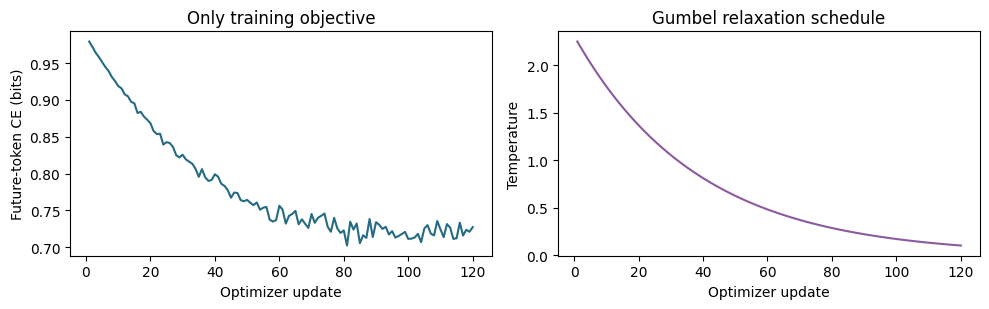

In [ ]:
torch.manual_seed(11)
model = HybridTransformerGRU(cfg).to(DEVICE)
draw_train = make_renewal_sampler(seed=101)
trace = train_model(model, draw_train, steps=120, batch_size=32)
final_tau = trace["tau"][-1]
final_report = final_diagnostics(model, test_window.to(DEVICE), final_tau)

print("Completed optimizer updates:", len(trace["step"]))
print("Temperature:", trace["tau"][0], "->", round(final_tau, 6))
print("Final held-out CE (bits/token):", round(final_report["ce_bits"], 6))
print("Final mean probability-vector L2:", round(final_report["mean_l2"], 6))
print("Compared probability arrays:", tuple(final_report["transformer_probs"].shape))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(trace["step"], trace["ce_bits"], color="#246B83")
axes[0].set(xlabel="Optimizer update", ylabel="Future-token CE (bits)", title="training objective")
axes[1].plot(trace["step"], trace["tau"], color="#8C5A9E")
axes[1].set(xlabel="Optimizer update", ylabel="Temperature", title="Gumbel relaxation schedule")
fig.tight_layout()
plt.show()

## 11. What to write in your .py file, and in what order

1. Write `HybridConfig`, `split_window`, and the shape checks. Verify H+L tokens yields L targets.
2. Write `SharedCausalHead.select`. Inspect `probs`, `onehot`, and `representation` separately.
3. Write the history encoder and the Transformer selector. Verify the causal-prefix test.
4. Write `transition`. Its input is one observed token plus one selected state vector.
5. Write `forward` by following the time table. Verify first-token scoring and L−1 transitions.
6. Write `prediction_loss`, `train_step`, and `train_model`. Verify gradients before a long run.
7. Write `final_diagnostics` separately. Verify matching histories and no diagnostic gradients.
8. Add a small `main()` only after the architecture works. Put its call under
   `if __name__ == "__main__":` so importing the file never starts training.

Copy concepts and signatures into your own implementation, then use the following cell to test it.
The current old v2 file does **not** implement this API yet, so the switch starts off.
Checkpoint saving, general process adapters, and larger experiments can be added later as explicit
steps. The draft does not silently reintroduce the old analysis runner or loss terms.

In [11]:
# After you write HybridConfig and HybridTransformerGRU in your .py file:
USE_MY_PY_IMPLEMENTATION = False
if USE_MY_PY_IMPLEMENTATION:
    import importlib.util
    source = Path("/Users/tisornnaphattalung/Desktop/Quantum/URECA/LLM_final_version/model_modeularised/hybrid_transformer_GRU_v2.py")
    import sys
    spec = importlib.util.spec_from_file_location("my_hybrid_v2", source)
    my_hybrid = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = my_hybrid  # Needed by dataclass type inspection.
    spec.loader.exec_module(my_hybrid)
    for name in run_contract_tests(my_hybrid.HybridTransformerGRU, my_hybrid.HybridConfig):
        print("PASS YOUR .PY:", name)
else:
    print("Notebook reference tested. Your .py file has not been imported or modified.")

Notebook reference tested. Your .py file has not been imported or modified.


## 12. Check your understanding

Try answering before reading the solutions.

* Why does the first prediction require no GRU update?
* Why does this model still train the Transformer without a separate Transformer CE?
* Why are A and B different layers even though the causal head is shared?
* Why is the final diagnostic Transformer slice `[:, H:]`, not `[:, H-1:-1]`?
* Does a low final L2 prove that the model discovered the correct causal states?

<details><summary>Answers</summary>

The handoff state already summarizes every observed history token and therefore emits the first
future distribution. The continuation CE backpropagates through the shared state representation
and the straight-through Transformer selector. A maps encoder outputs of size D; B maps GRU
proposals of size S; both select rows from the same E. The diagnostic compares states *after*
each future token; the alternative slice would compare predictive states *before* those tokens.
Finally, two branches can agree on an uninformative state. L2 measures consistency, not predictive
sufficiency, minimality, or correctness of the inferred process.

</details>

The test suite verifies implementation contracts, not model convergence. The online data generation,
number of scored targets, and single continuation objective differ from the earlier experiment;
do not interpret this short run as a controlled performance comparison with the old results.

## 13. Full experiment: a 15-state renewal process from your library

This extension runs the same architecture on a process defined by **your `HMM_processes.py`**.
It is a full 30,000-update experiment, distinct from the 120-update demonstration above.
At your request, this extension records a **probability-vector L2 learning curve**, evaluated without
gradients. This supersedes the final-only reporting rule for this experiment; the loss remains CE only.

We choose `F(n)=1/15` for n=0,…,14 zeros between events. The theoretical state is the age since the last 1:
`P(1 | age=a)=1/(15-a)`, `1` resets the age to 0, and `0` increments it. The last age emits 1 surely.
All 15 hazards differ, so all 15 recurrent states have distinct predictions; the library also checks
minimality. Every 20-token history contains an event and identifies the true current age.

Settings: H=20, L=10, D=16, four attention layers, state dimension 32, **32 available learned states**,
batch size 128, Adam at 0.001 with zero weight decay, and temperature 2.25→0.1 over 30,000 updates.
The available learned-state count is a capacity setting, not the number assumed to be discovered.
There is one handoff per fresh window, and no state supervision or auxiliary objective.

Data streams are separate: training, a fixed validation probe for curves, state-label alignment,
and final test. Theory state labels are used only after training for the comparisons.

In [37]:
import sys
import json
import hashlib
import time
from dataclasses import asdict
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.sparse.csgraph import connected_components

MODULE_DIR = Path("/Users/tisornnaphattalung/Desktop/Quantum/URECA/LLM_final_version/model_modeularised")
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))
import HMM_processes as hmm

PROCESS_NAME = "renewal"
PROCESS_PARAMS = {"F": [1.0 / 15] * 15}
process_spec = hmm.PROCESS[PROCESS_NAME]
theory_T = process_spec["transition"](PROCESS_PARAMS)
theory_E = process_spec["state_map"](PROCESS_PARAMS)
theory_V = process_spec["vocab_size"](PROCESS_PARAMS)
hmm.check_map(theory_T, theory_E, theory_V)
theory_M = hmm.joint_map(theory_T, theory_E)  # [state, next state, token]
theory_pi = hmm.stationary_dist(theory_T)
theory_emission = hmm.emission_dist(theory_T, theory_E)
theory_minimal = hmm.epsilon_machine(theory_T, theory_E)
assert theory_minimal["n_states"] == 15
theory_hmu = hmm.entropy_rate(theory_T, theory_E, theory_pi)
print("Loaded:", Path(hmm.__file__).resolve())
print("Theoretical states:", theory_minimal["n_states"])
print("Theoretical entropy rate (bits/token):", round(theory_hmu, 8))
display(pd.DataFrame({"age": range(15), "P(1)": theory_emission[:, 1],
                      "stationary probability": theory_pi}))

Loaded: /Users/tisornnaphattalung/Desktop/Quantum/URECA/LLM_final_version/model_modeularised/HMM_processes.py
Theoretical states: 15
Theoretical entropy rate (bits/token): 0.48836132


,age,P(1),stationary probability
0,0,0.066667,0.125000
1,1,0.071429,0.116667
2,2,0.076923,0.108333
3,3,0.083333,0.100000
4,4,0.090909,0.091667
5,5,0.100000,0.083333
6,6,0.111111,0.075000
7,7,0.125000,0.066667
8,8,0.142857,0.058333
9,9,0.166667,0.050000


### A reusable batch sampler for any process in the registry

The library supplies the joint symbol-labelled transition map M. For speed, the sampler below draws
all rows of a batch together using that same map. It samples `(next_state, token)` jointly, just as
`HMM_processes.tokens_from_map` does. It does not implement a separate renewal model.
`states[:, j]` denotes the theoretical state **before** token j. Training receives only `tokens`.

In [38]:
class RegisteredProcessSampler:
    def __init__(self, transition, state_map, seed):
        self.T = np.asarray(transition, dtype=float)
        self.M = hmm.joint_map(self.T, np.asarray(state_map, dtype=float))
        self.pi = hmm.stationary_dist(self.T)
        self.V = self.M.shape[-1]
        self.cdf = self.M.reshape(len(self.T), -1).cumsum(axis=-1)
        self.cdf /= self.cdf[:, -1:]
        self.rng = np.random.default_rng(seed)

    def sample(self, batch_size, total_len, return_states=False):
        state = self.rng.choice(len(self.T), size=batch_size, p=self.pi)
        tokens = np.empty((batch_size, total_len), dtype=np.int64)
        states = np.empty((batch_size, total_len + 1), dtype=np.int64)
        states[:, 0] = state
        for j in range(total_len):
            u = self.rng.random(batch_size)
            flat = (self.cdf[state] <= u[:, None]).sum(axis=-1)
            state, token = flat // self.V, flat % self.V
            tokens[:, j] = token
            states[:, j + 1] = state
        result = torch.from_numpy(tokens)
        return (result, states) if return_states else result

    def __call__(self, batch_size, total_len):
        return self.sample(batch_size, total_len)


def exact_window_ce(tokens, history_len):
    x = tokens.cpu().numpy()
    probs = hmm.filter_probs(theory_M, theory_pi, x)
    target_probs = np.take_along_axis(probs[:, history_len:],
                                      x[:, history_len:, None], axis=-1)[..., 0]
    return float(-np.log2(target_probs).mean())


# Check the generic sampler against the renewal state update and theoretical stationary frequencies.
sample_check = RegisteredProcessSampler(theory_T, theory_E, seed=303)
check_tokens, check_states = sample_check.sample(4096, 30, return_states=True)
assert np.all(check_states[:, 1:] == np.where(check_tokens.numpy() == 1, 0, check_states[:, :-1] + 1))
assert check_states.max() == 14
freq = np.bincount(check_states[:, :-1].ravel(), minlength=15) / check_tokens.numel()
assert np.max(np.abs(freq - theory_pi)) < 0.01
print("Sampler state-update and stationary-frequency checks passed.")

Sampler state-update and stationary-frequency checks passed.


### Train once; reuse the saved completed run

The cell below performs the full run if there is no matching completed checkpoint. On subsequent
notebook runs it loads the saved result. Set `FORCE_RETRAIN=True` to run again. A source/configuration
fingerprint separates results when the architecture or experiment changes. Completed results include
the final parameters, settings, every training loss, and the validation CE/L2 history.

Validation is evaluated every 250 updates. L2 compares the full probability vectors after the same
future observations, using the current temperature without Gumbel noise. Changes in its curve can
reflect both learned logits and temperature sharpening; the temperature is plotted alongside it.
No checkpoint is selected using validation or L2. We keep the actual last update.

The loss curve is the sampled-state training CE. The validation curve uses deterministic state choices;
the two need not coincide. The exact CE reference scores the same validation tokens, rather than
substituting the population entropy rate for a particular realized sample.

In [ ]:
renewal15_cfg = HybridConfig(vocab_size=2, n_states=32, state_dim=32,
                             d_model=16, n_layers=4, history_len=30, rollout_len=2)
EXPERIMENT = dict(model=asdict(renewal15_cfg), process=PROCESS_NAME, params=PROCESS_PARAMS,
                  steps=30_000, batch_size=128, lr=1e-3, tau_start=2.50, tau_end=0.5,
                  eval_every=250, validation_rows=512, alignment_rows=4096, test_rows=4096,
                  model_seed=17, train_seed=1101, validation_seed=2202,
                  alignment_seed=3303, test_seed=4404, device="cpu", threads=2)
notebook_path = MODULE_DIR / "hybrid_model_test.ipynb"
_nb = json.loads(notebook_path.read_text())
_source = "\n".join("".join(c.get("source", [])) for c in _nb["cells"]
                    if c["cell_type"] == "code" and any(key in "".join(c.get("source", []))
                    for key in ("class CausalAttentionBlock", "class SharedCausalHead",
                                "class HybridTransformerGRU", "def train_step",
                                "def final_diagnostics", "class RegisteredProcessSampler")))
SOURCE_HASH = hashlib.sha256((_source + Path(hmm.__file__).read_text()).encode()).hexdigest()
EXPERIMENT["source_sha256"] = SOURCE_HASH
RUN_ID = hashlib.sha256(json.dumps(EXPERIMENT, sort_keys=True).encode()).hexdigest()[:12]
RUN_DIR = MODULE_DIR / "notebook_results" / f"renewal15_{RUN_ID}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
print("Result directory:", RUN_DIR)


def run_renewal15_experiment(force=False):
    checkpoint_path = RUN_DIR / "completed.pt"
    if checkpoint_path.exists() and not force:
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if saved["experiment"] != EXPERIMENT:
            raise ValueError("saved configuration does not match this experiment")
        trained = HybridTransformerGRU(renewal15_cfg)
        trained.load_state_dict(saved["model_state"])
        print(f"Loaded completed {saved['updates']:,}-update run ({saved['seconds']/60:.1f} training minutes).")
        return trained, saved

    torch.set_num_threads(EXPERIMENT["threads"])
    torch.manual_seed(EXPERIMENT["model_seed"])
    trained = HybridTransformerGRU(renewal15_cfg)
    optimizer = torch.optim.Adam(trained.parameters(), lr=EXPERIMENT["lr"], weight_decay=0.0)
    train_source = RegisteredProcessSampler(theory_T, theory_E, EXPERIMENT["train_seed"])
    validation_source = RegisteredProcessSampler(theory_T, theory_E, EXPERIMENT["validation_seed"])
    validation = validation_source(EXPERIMENT["validation_rows"], renewal15_cfg.total_len)
    exact_validation = exact_window_ce(validation, renewal15_cfg.history_len)
    training_history, evaluation_history = [], []
    start_time = time.perf_counter()

    def record(update, tau):
        values = final_diagnostics(trained, validation, tau)
        evaluation_history.append(dict(update=update, tau=tau, ce_bits=values["ce_bits"],
                                        mean_l2=values["mean_l2"], exact_ce_bits=exact_validation))
        elapsed = time.perf_counter() - start_time
        progress = dict(update=update, total=EXPERIMENT["steps"], seconds=elapsed,
                        validation_ce=values["ce_bits"], l2=values["mean_l2"], tau=tau)
        (RUN_DIR / "progress.json").write_text(json.dumps(progress, indent=2))
        pd.DataFrame(evaluation_history).to_csv(RUN_DIR / "validation_history.csv", index=False)
        if update == 0 or update % 1000 == 0 or update == EXPERIMENT["steps"]:
            print(f"{update:6,d}/{EXPERIMENT['steps']:,} | CE {values['ce_bits']:.6f} | "
                  f"L2 {values['mean_l2']:.4f} | tau {tau:.3f} | {elapsed/60:.1f} min", flush=True)

    record(0, EXPERIMENT["tau_start"])
    for step in range(EXPERIMENT["steps"]):
        tau = temperature(step, EXPERIMENT["steps"], EXPERIMENT["tau_start"], EXPERIMENT["tau_end"])
        window = train_source(EXPERIMENT["batch_size"], renewal15_cfg.total_len)
        ce = train_step(trained, window, optimizer, tau)
        if not math.isfinite(ce):
            raise RuntimeError(f"non-finite CE at update {step+1}; experiment not complete")
        training_history.append(dict(update=step+1, ce_bits=ce, tau=tau))
        if (step + 1) % EXPERIMENT["eval_every"] == 0 or step + 1 == EXPERIMENT["steps"]:
            record(step + 1, tau)

    saved = dict(experiment=EXPERIMENT, model_state=trained.state_dict(),
                 updates=EXPERIMENT["steps"], seconds=time.perf_counter()-start_time,
                 training_history=training_history, evaluation_history=evaluation_history,
                 torch_version=str(torch.__version__))
    torch.save(saved, checkpoint_path)
    pd.DataFrame(training_history).to_csv(RUN_DIR / "training_history.csv", index=False)
    (RUN_DIR / "experiment.json").write_text(json.dumps(EXPERIMENT, indent=2))
    return trained, saved


FORCE_RETRAIN = False
renewal15_model, renewal15_run = run_renewal15_experiment(force=FORCE_RETRAIN)

Result directory: /Users/tisornnaphattalung/Desktop/Quantum/URECA/LLM_final_version/model_modeularised/notebook_results/renewal15_391faf433e66
     0/30,000 | CE 1.066859 | L2 0.0462 | tau 2.500 | 0.0 min
 1,000/30,000 | CE 0.480705 | L2 0.9424 | tau 2.370 | 0.4 min
 2,000/30,000 | CE 0.484758 | L2 1.0281 | tau 2.246 | 0.8 min
 3,000/30,000 | CE 0.480691 | L2 1.0364 | tau 2.128 | 1.1 min
 4,000/30,000 | CE 0.480897 | L2 1.0383 | tau 2.017 | 1.5 min
 5,000/30,000 | CE 0.480654 | L2 1.0393 | tau 1.912 | 1.9 min
 6,000/30,000 | CE 0.485259 | L2 1.0424 | tau 1.812 | 2.2 min
 7,000/30,000 | CE 0.481985 | L2 1.0382 | tau 1.717 | 2.6 min
 8,000/30,000 | CE 0.478812 | L2 1.0429 | tau 1.628 | 3.0 min
 9,000/30,000 | CE 0.482592 | L2 1.0448 | tau 1.543 | 3.3 min
10,000/30,000 | CE 0.480157 | L2 1.0517 | tau 1.462 | 3.7 min
11,000/30,000 | CE 0.482440 | L2 1.0471 | tau 1.386 | 4.1 min
12,000/30,000 | CE 0.483248 | L2 1.0567 | tau 1.313 | 4.5 min
13,000/30,000 | CE 0.478396 | L2 1.0557 | tau 1.245

### Loss and full-probability L2 during training

The left panel shows the only optimized loss (a 250-update moving average plus raw values) and
held-out validation CE. The middle panel is the requested mean Euclidean distance across the full
32-way Transformer and GRU selection vectors. Its range is 0 to sqrt(2). The right panel records
the temperature used by both branches. All plotted values come from the saved run.

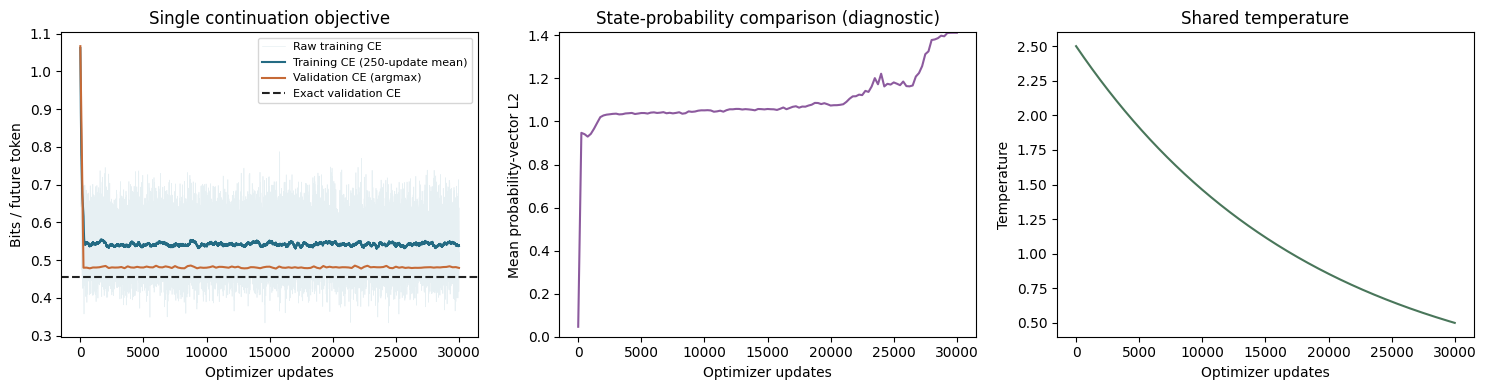

In [44]:
train_df = pd.DataFrame(renewal15_run["training_history"])
eval_df = pd.DataFrame(renewal15_run["evaluation_history"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(train_df["update"], train_df.ce_bits,
             color="#BCD4DE", alpha=.35, linewidth=.5, label="Raw training CE")
axes[0].plot(train_df["update"], train_df.ce_bits.rolling(250, min_periods=1).mean(),
             color="#246B83", label="Training CE (250-update mean)")
axes[0].plot(eval_df["update"], eval_df.ce_bits, color="#C66A36", label="Validation CE (argmax)")
axes[0].axhline(eval_df.exact_ce_bits.iloc[-1], color="#222222", linestyle="--", label="Exact validation CE")
axes[0].set(title="Single continuation objective", xlabel="Optimizer updates", ylabel="Bits / future token")
axes[0].legend(fontsize=8)
axes[1].plot(eval_df["update"], eval_df.mean_l2, color="#8C5A9E")
axes[1].set(title="State-probability comparison (diagnostic)", xlabel="Optimizer updates",
             ylabel="Mean probability-vector L2", ylim=(0, math.sqrt(2)))
axes[2].plot(train_df["update"], train_df.tau, color="#49765A")
axes[2].set(title="Shared temperature", xlabel="Optimizer updates", ylabel="Temperature")
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=180, bbox_inches="tight")
fig.savefig(RUN_DIR / "training_curves.pdf", bbox_inches="tight")
plt.show()

### Final held-out evaluation and exact extraction

We extract the GRU's deterministic evaluation update by enumerating **every codebook state and
observable**, not by estimating transitions from counts. For each code i and token x:

$$\delta(i,x)=\arg\max B\,\operatorname{GRUCell}(\operatorname{onehot}(x),E_i),\qquad
M^{\rm learned}_{i,j,x}=p(x\mid i)\,\mathbf{1}\{j=\delta(i,x)\}.$$

This separates the deterministic state-update rule from stochastic symbol emission. The trained
emission probabilities supply the edge weights; observed transition frequencies do not replace them.
The counts below are used only for label alignment and occupancy.

The raw machine can include unused codes, transient states, or several closed communicating classes.
We take states reachable from Transformer starts seen in the separate alignment sample, identify
closed recurrent classes, and minimize each class using the library's probability-preserving partition
refinement (`tol=1e-10`). We do not force the answer to have 15 states or merge merely similar emissions.

Each minimal recurrent component is a candidate epsilon-machine for its own learned stationary process.
It need not equal the true renewal machine. With multiple closed classes, there is no unique single
recurrent component to select without a starting distribution. The report keeps every reachable class.
Transient codes remain in the saved raw machine and the hybrid's CE, even though they are omitted
from the stationary recurrent-machine diagram.

In [46]:
@torch.no_grad()
def extract_codebook_machine(model):
    E = model.causal_head.state_matrix
    K, V = model.cfg.n_states, model.cfg.vocab_size
    emission = model.causal_head.emission(E).softmax(-1).cpu().numpy().astype(float)
    delta = np.empty((K, V), dtype=np.int64)
    for x in range(V):
        tokens = torch.full((K,), x, dtype=torch.long, device=E.device)
        proposal = model.gru_cell(F.one_hot(tokens, V).to(E.dtype), E)
        delta[:, x] = model.gru_selector(proposal).argmax(-1).cpu().numpy()
    joint = np.zeros((K, K, V))
    for i in range(K):
        for x in range(V):
            joint[i, delta[i, x], x] = emission[i, x]
    assert np.allclose(joint.sum(axis=(1, 2)), 1)
    return dict(delta=delta, emission=emission, M=joint)


@torch.no_grad()
def evaluate_and_trace(model, windows, tau, raw_machine, batch_size=256):
    was = model.training
    model.eval()
    ce_sum, l2_sum, n = 0.0, 0.0, 0
    predictive_states, starts, qT, qG = [], [], [], []
    try:
        for batch in windows.split(batch_size):
            h, y = split_window(batch, model.cfg)
            result = final_diagnostics(model, batch, tau)
            count = y.numel()
            ce_sum += result["ce_bits"] * count
            l2_sum += result["mean_l2"] * count
            n += count
            qT.append(result["transformer_probs"])
            qG.append(result["gru_probs"])
            state = model.initial_state(h, tau)
            starts.append(state.ids.cpu().numpy())
            ids = []
            for k in range(model.cfg.rollout_len):
                ids.append(state.ids.cpu().numpy())
                following = model.transition(state, y[:, k], tau)
                predicted_successor = raw_machine["delta"][ids[-1], y[:, k].cpu().numpy()]
                assert np.array_equal(predicted_successor, following.ids.cpu().numpy())
                state = following
            predictive_states.append(np.stack(ids, axis=1))
    finally:
        model.train(was)
    return dict(ce_bits=ce_sum/n, mean_l2=l2_sum/n,
                 predictive_states=np.concatenate(predictive_states), starts=np.concatenate(starts),
                 qT=torch.cat(qT), qG=torch.cat(qG))


def recurrent_minimal_machine(raw, initial_states):
    reached = set(map(int, np.unique(initial_states)))
    todo = list(reached)
    while todo:
        s = todo.pop()
        for x in np.flatnonzero(raw["emission"][s] > 0):
            successor = int(raw["delta"][s, x])
            if successor not in reached:
                reached.add(successor)
                todo.append(successor)
    reachable = np.array(sorted(reached), dtype=int)
    adjacency = raw["M"].sum(axis=-1)[np.ix_(reachable, reachable)] > 0
    n_components, labels = connected_components(adjacency, directed=True, connection="strong")
    closed = [reachable[labels == k] for k in range(n_components)
              if not adjacency[np.ix_(labels == k, labels != k)].any()]
    closed.sort(key=lambda ids: int(ids.min()))
    quotients, groups, component_ids = [], [], []
    raw_to_minimal = np.full(len(raw["delta"]), -1, dtype=int)
    offset = 0
    for c, ids in enumerate(closed):
        joint = raw["M"][np.ix_(ids, ids)]
        quotient, local_labels = hmm.minimise(joint, tol=1e-10)
        quotients.append(quotient)
        for k in range(len(quotient)):
            members = ids[local_labels == k]
            groups.append(members.tolist())
            component_ids.append(c)
            raw_to_minimal[members] = offset+k
        offset += len(quotient)
    minimal = np.zeros((offset, offset, raw["M"].shape[-1]))
    start = 0
    for quotient in quotients:
        stop = start+len(quotient)
        minimal[start:stop, start:stop] = quotient
        start = stop
    assert np.allclose(minimal.sum(axis=(1, 2)), 1)
    return dict(M=minimal, groups=groups, components=component_ids,
                 raw_to_minimal=raw_to_minimal, reachable=reachable,
                 n_closed_classes=len(closed), recurrent_raw=np.concatenate(closed))


final_temperature = EXPERIMENT["tau_end"]
learned_raw = extract_codebook_machine(renewal15_model)
alignment_source = RegisteredProcessSampler(theory_T, theory_E, EXPERIMENT["alignment_seed"])
alignment_tokens, alignment_states = alignment_source.sample(
    EXPERIMENT["alignment_rows"], renewal15_cfg.total_len, return_states=True)
alignment = evaluate_and_trace(renewal15_model, alignment_tokens, final_temperature, learned_raw)
learned_minimal = recurrent_minimal_machine(learned_raw, alignment["starts"])

test_source = RegisteredProcessSampler(theory_T, theory_E, EXPERIMENT["test_seed"])
full_test_tokens, full_test_states = test_source.sample(
    EXPERIMENT["test_rows"], renewal15_cfg.total_len, return_states=True)
test_result = evaluate_and_trace(renewal15_model, full_test_tokens, final_temperature, learned_raw)
exact_test_ce = exact_window_ce(full_test_tokens, renewal15_cfg.history_len)
test_metrics = dict(updates=renewal15_run["updates"], training_minutes=renewal15_run["seconds"]/60,
                    test_ce_bits=test_result["ce_bits"], exact_test_ce_bits=exact_test_ce,
                    excess_test_ce_bits=test_result["ce_bits"]-exact_test_ce,
                    mean_probability_l2=test_result["mean_l2"], theory_states=15,
                    available_codes=renewal15_cfg.n_states,
                    used_predictive_codes=int(np.unique(test_result["predictive_states"]).size),
                    reachable_codes=int(len(learned_minimal["reachable"])),
                    recurrent_codes=int(len(learned_minimal["recurrent_raw"])),
                    minimal_recurrent_states=int(len(learned_minimal["M"])),
                    recurrent_classes=int(learned_minimal["n_closed_classes"]))
display(pd.Series(test_metrics, name="Final result").to_frame())

,Final result
updates,30000.000000
training_minutes,11.204153
test_ce_bits,0.550926
exact_test_ce_bits,0.491813
excess_test_ce_bits,0.059113
mean_probability_l2,1.412418
theory_states,15.000000
available_codes,32.000000
used_predictive_codes,3.000000
reachable_codes,3.000000


### Align labels without hiding missing states

State names are arbitrary. On the **separate alignment sample**, count pairs of `(learned recurrent
state, true age)` at prediction boundaries. Use a one-to-one assignment maximizing total agreement.
Only positive-count pairs are accepted. Extra learned states remain extra, and missing theory ages
remain missing. This relabelling is for plots only; it does not modify or retrain the model.

The same frozen assignment is then applied to the final test set. The heatmap shows the resulting
conditional occupancy by true age, including transient codes and states outside the alignment-start
reachable set. A diagonal is evidence of correspondence; matching state counts alone is not.

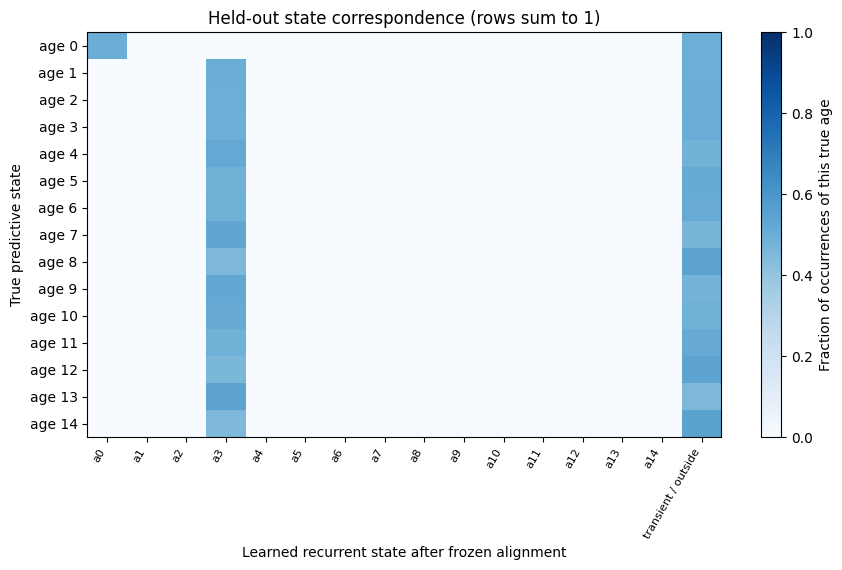

One-to-one state agreement on final test: 0.113
Missing theory ages: [1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | extra recurrent states: []


In [47]:
H, L = renewal15_cfg.history_len, renewal15_cfg.rollout_len
N_min = len(learned_minimal["M"])
align_ids = learned_minimal["raw_to_minimal"][alignment["predictive_states"]]
align_age = alignment_states[:, H:H+L]
alignment_counts = np.zeros((N_min, 15), dtype=np.int64)
valid = align_ids >= 0
np.add.at(alignment_counts, (align_ids[valid], align_age[valid]), 1)
rows, cols = linear_sum_assignment(-alignment_counts)
minimal_to_age = {int(r): int(c) for r,c in zip(rows,cols) if alignment_counts[r,c] > 0}
age_to_minimal = {a:r for r,a in minimal_to_age.items()}
extras = [r for r in range(N_min) if r not in minimal_to_age]
ordered_minimal = [age_to_minimal[a] for a in range(15) if a in age_to_minimal] + extras
minimal_to_axis = {r:a for r,a in minimal_to_age.items()}
minimal_to_axis.update({r:15+i for i,r in enumerate(extras)})
axis_labels = [f"a{a}" for a in range(15)] + [f"extra R{r}" for r in extras]
axis_size = len(axis_labels)
missing_ages = [a for a in range(15) if a not in age_to_minimal]

test_min_ids = learned_minimal["raw_to_minimal"][test_result["predictive_states"]]
test_age = full_test_states[:, H:H+L]
mapped_age = np.full(test_min_ids.shape,-1)
for r,a in minimal_to_age.items():mapped_age[test_min_ids==r]=a
test_metrics["aligned_state_accuracy"] = float((mapped_age==test_age).mean())
test_metrics["transient_or_unrepresented_fraction"] = float((test_min_ids<0).mean())
test_metrics["missing_theory_ages"] = missing_ages
test_metrics["extra_recurrent_states"] = extras

test_counts = np.zeros((15, axis_size+1),dtype=int)
for r in range(N_min):
    mask = test_min_ids==r
    np.add.at(test_counts, (test_age[mask], np.full(mask.sum(),minimal_to_axis[r])), 1)
mask = test_min_ids<0
np.add.at(test_counts,(test_age[mask],np.full(mask.sum(),axis_size)),1)
conditional_counts = test_counts / np.maximum(test_counts.sum(axis=1,keepdims=True),1)
fig, ax = plt.subplots(figsize=(max(9,axis_size*.45),5.8))
im=ax.imshow(conditional_counts,vmin=0,vmax=1,cmap="Blues",aspect="auto")
ax.set(xticks=range(axis_size+1),xticklabels=axis_labels+["transient / outside"],
        yticks=range(15),yticklabels=[f"age {a}" for a in range(15)],
        xlabel="Learned recurrent state after frozen alignment",ylabel="True predictive state",
        title="Held-out state correspondence (rows sum to 1)")
plt.setp(ax.get_xticklabels(),rotation=60,ha="right",fontsize=8)
fig.colorbar(im,ax=ax,label="Fraction of occurrences of this true age")
fig.tight_layout()
fig.savefig(RUN_DIR/"state_correspondence.png",dpi=180,bbox_inches="tight")
plt.show()
print("One-to-one state agreement on final test:",round(test_metrics["aligned_state_accuracy"],4))
print("Missing theory ages:",missing_ages,"| extra recurrent states:",extras)

### Compare the theoretical and learned recurrent machines

These diagrams now call **`plotting._draw_machine`**, the same renderer used by
`plotting.plot_machine_graph` in this folder. The layout, node colors, node labels, edge notation
`symbol|probability`, and self-loop annotations therefore match your other model figures.
Node π is the stationary probability, not short-window visitation frequency.

The renderer omits edges of probability ≤ 0.01 for readability and lists self-loops on the node.
This is a drawing threshold only: extraction, recurrent-class analysis, minimization, saved arrays,
and all numerical transition comparisons retain every positive-probability transition. For multiple
recurrent classes, stationary class weights follow the empirical Transformer start distribution on
the separate alignment set. The raw transition tables preserve the exact small probabilities.

**Why the raw and recurrent diagrams differ:** these are two views of the same final model,
not different training runs. The raw graph includes temporary states used after a Transformer
initialization. The recurrent graph retains the closed recurrent classes reached if the model
continues indefinitely without being reinitialized. In this 15-state experiment, eight reachable
codes are transient and only L1 is recurrent. Both symbols loop at L1; the recurrent drawing
renames it R0. Its large oval is just the renderer's self-loop. The assignment `R0 → a0` is a
post-hoc label match, not evidence of recovering theoretical age 0.

A transient state's stationary weight π=0 does not mean it is never used in a short rollout.
The repeated fresh Transformer initializations can revisit transient states on every training
window. The displayed π describes indefinite generation with no such resets.


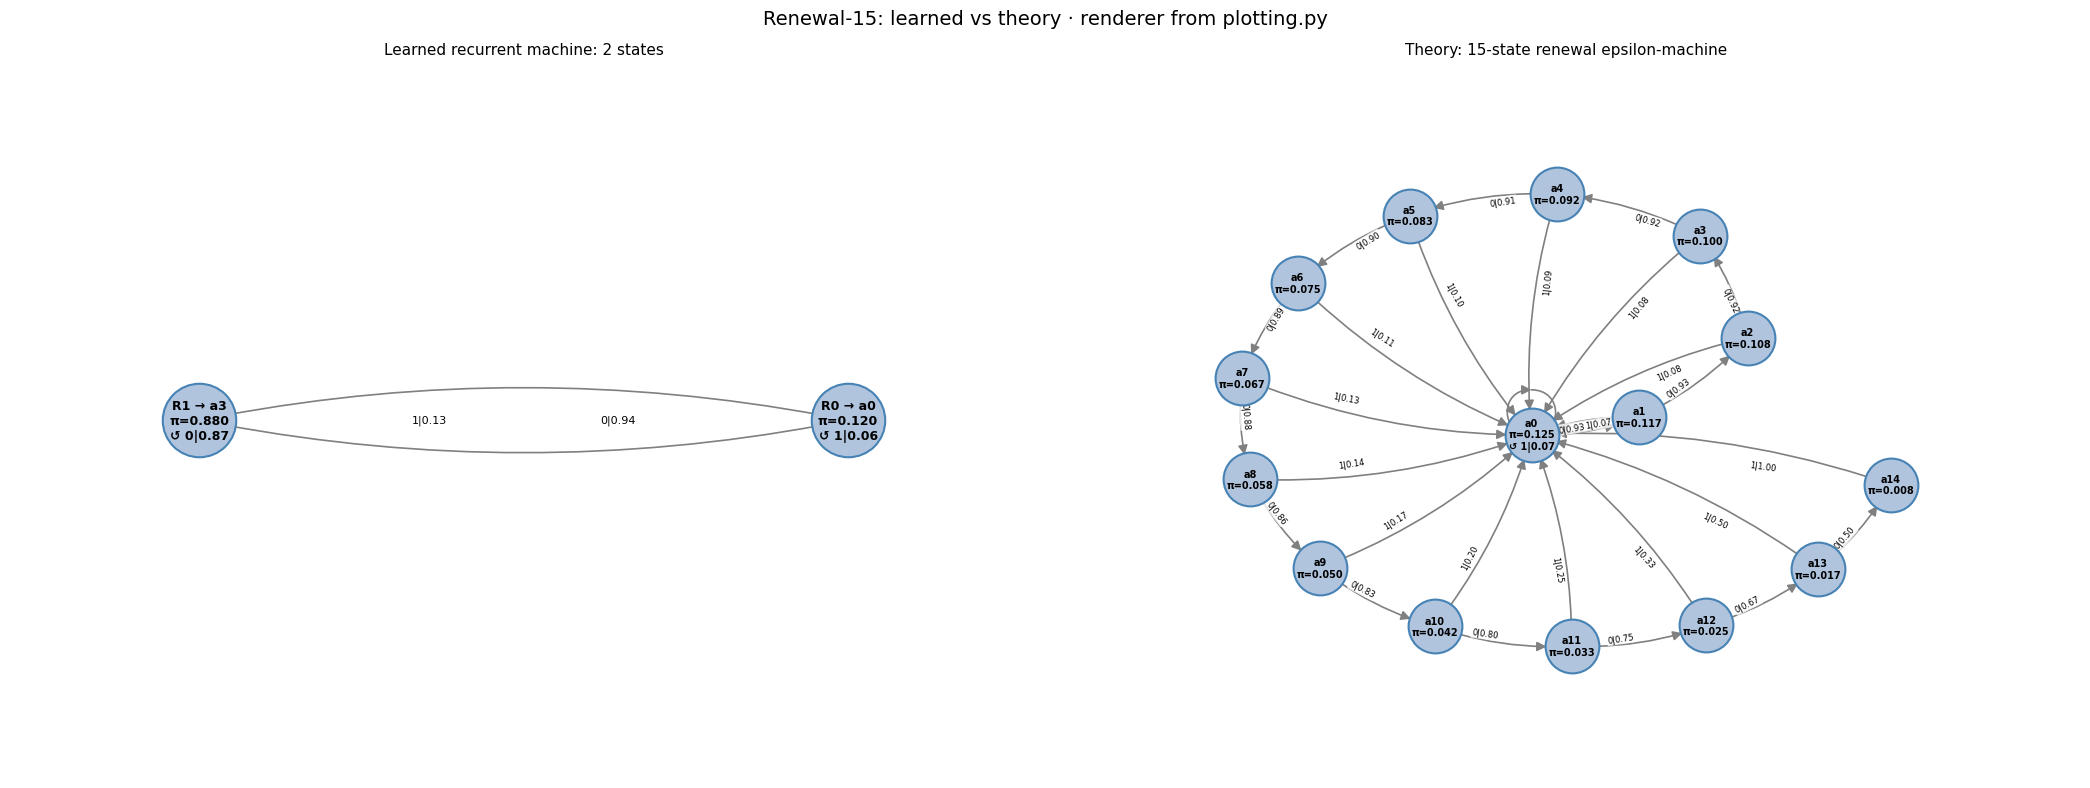

In [48]:
import plotting as project_plotting

def stationary_from_initial(joint, initial):
    """Stationary mixture of recurrent classes reached from a specified start distribution."""
    transition=joint.sum(axis=-1).copy()
    transition/=transition.sum(axis=1,keepdims=True)
    initial=np.asarray(initial,dtype=float);initial=initial/initial.sum()
    n_components,labels=connected_components(transition>0,directed=True,connection="strong")
    closed=[np.flatnonzero(labels==c) for c in range(n_components)
            if not (transition[np.ix_(labels==c,labels!=c)]>0).any()]
    recurrent=np.concatenate(closed)
    transient=np.setdiff1d(np.arange(len(transition)),recurrent)
    stationary=np.zeros(len(transition))
    for ids in closed:
        mass=initial[ids].sum()
        if len(transient):
            Q=transition[np.ix_(transient,transient)]
            exit_probability=transition[np.ix_(transient,ids)].sum(axis=1)
            absorption=np.linalg.solve(np.eye(len(transient))-Q,exit_probability)
            mass+=initial[transient]@absorption
        stationary[ids]=mass*hmm.stationary_dist(transition[np.ix_(ids,ids)])
    stationary=np.maximum(stationary,0);stationary/=stationary.sum()
    assert np.allclose(stationary@transition,stationary,atol=1e-7)
    return stationary

def draw_project_machine(ax,joint,stationary,labels,title):
    emission=joint.sum(axis=1)
    successors=joint.argmax(axis=1)
    project_plotting._draw_machine(ax,successors,emission,stationary,labels,title)
    ax.margins(.22)

raw_ids=learned_minimal["reachable"]
raw_reachable_M=learned_raw["M"][np.ix_(raw_ids,raw_ids)]
starts_count=np.bincount(alignment["starts"],minlength=renewal15_cfg.n_states)[raw_ids]
reachable_pi=stationary_from_initial(raw_reachable_M,starts_count)
raw_pi=np.zeros(renewal15_cfg.n_states);raw_pi[raw_ids]=reachable_pi
minimal_pi=np.array([raw_pi[group].sum() for group in learned_minimal["groups"]])
fig,axes=plt.subplots(1,2,figsize=(21,8))
labels=[f"R{r}"+(f" → a{minimal_to_age[r]}" if r in minimal_to_age else " (extra)") for r in range(N_min)]
draw_project_machine(axes[0],learned_minimal["M"],minimal_pi,labels,
                     f"Learned recurrent machine: {N_min} states")
draw_project_machine(axes[1],theory_M,theory_pi,[f"a{a}" for a in range(15)],
                     "Theory: 15-state renewal epsilon-machine")
fig.suptitle("Renewal-15: learned vs theory · renderer from plotting.py",fontsize=14)
fig.tight_layout()
fig.savefig(RUN_DIR/"machines_theory_vs_learned.png",dpi=180,bbox_inches="tight")
fig.savefig(RUN_DIR/"machines_theory_vs_learned.pdf",bbox_inches="tight")
plt.show()

### Raw reachable machine: keep the transient states visible

The previous diagram shows the minimized recurrent generator. This one retains **every raw code
reachable from the observed Transformer starts**, including transients. `rec` marks recurrent codes;
`trans` marks transient codes. The table gives the exact deterministic next-state rule and emission
probabilities, together with held-out use during short-window prediction.

An absorbing code has both symbol transitions back to itself. Once the deterministic rollout enters
it, the GRU cannot recover the renewal age. Repeated fresh Transformer initializations can still make
the finite-window loss differ from the autonomous long-run generator's behavior. State usage during
short rollouts and the number of recurrent causal states are therefore different measurements.

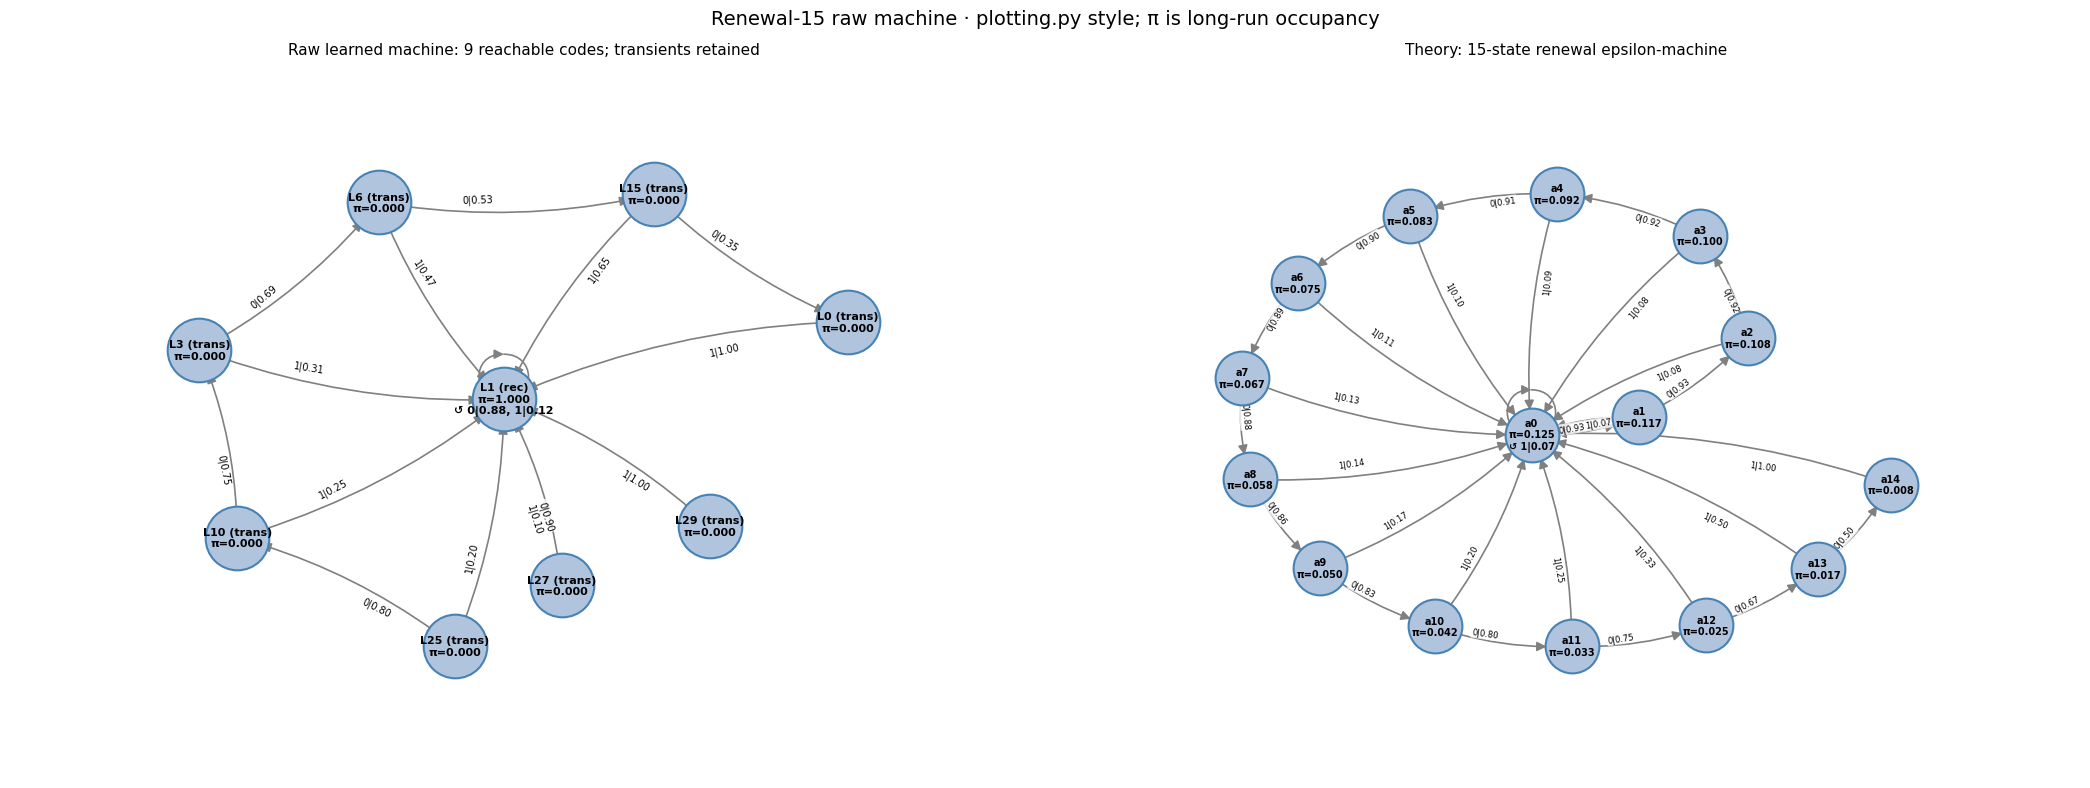

,code,kind,P0,P1,next0,next1,test_predictive_occupancy,transformer_start_fraction
0,L0,transient,0.003965,0.996035,L0,L1,0.001709,0.000000
1,L1,recurrent,0.882159,0.117841,L1,L1,0.871582,0.000000
2,L3,transient,0.690957,0.309043,L6,L1,0.013257,0.077637
3,L6,transient,0.533789,0.466211,L15,L1,0.009253,0.000000
4,L10,transient,0.752436,0.247564,L3,L1,0.007251,0.000000
5,L15,transient,0.354322,0.645678,L0,L1,0.004712,0.000000
6,L25,transient,0.800064,0.199936,L10,L1,0.008887,0.088867
7,L27,transient,0.902323,0.097677,L1,L1,0.082690,0.826904
8,L29,transient,0.000057,0.999943,L0,L1,0.000659,0.006592


In [19]:
raw_ids=learned_minimal["reachable"]
raw_reachable_M=learned_raw["M"][np.ix_(raw_ids,raw_ids)]
recurrent_set=set(map(int,learned_minimal["recurrent_raw"]))
raw_labels=[f"L{raw}"+(" (rec)" if int(raw) in recurrent_set else " (trans)") for raw in raw_ids]
fig,axes=plt.subplots(1,2,figsize=(21,8))
draw_project_machine(axes[0],raw_reachable_M,reachable_pi,raw_labels,
                     f"Raw learned machine: {len(raw_ids)} reachable codes; transients retained")
draw_project_machine(axes[1],theory_M,theory_pi,[f"a{a}" for a in range(15)],
                     "Theory: 15-state renewal epsilon-machine")
fig.suptitle("Renewal-15 raw machine · plotting.py style; π is long-run occupancy",fontsize=14)
fig.tight_layout()
fig.savefig(RUN_DIR/"raw_learned_machine.png",dpi=180,bbox_inches="tight")
fig.savefig(RUN_DIR/"raw_learned_machine.pdf",bbox_inches="tight")
plt.show()
occupancy=np.bincount(test_result["predictive_states"].ravel(),minlength=renewal15_cfg.n_states)
occupancy=occupancy/occupancy.sum()
start_counts=np.bincount(test_result["starts"],minlength=renewal15_cfg.n_states)
start_occupancy=start_counts/start_counts.sum()
raw_table=pd.DataFrame([dict(code=f"L{raw}",kind="recurrent" if int(raw) in recurrent_set else "transient",
                            P0=learned_raw["emission"][raw,0],P1=learned_raw["emission"][raw,1],
                            next0=f"L{learned_raw['delta'][raw,0]}",next1=f"L{learned_raw['delta'][raw,1]}",
                            test_predictive_occupancy=occupancy[raw],transformer_start_fraction=start_occupancy[raw])
                           for raw in raw_ids])
display(raw_table.round(6))
raw_table.to_csv(RUN_DIR/"raw_transition_table.csv",index=False)

### Compare symbol-labelled transition probabilities and update rules

The matrices below use a common axis: theory ages a0,…,a14, then extra learned states. A grey
**learned row** means no recurrent learned state was assigned to that true age. The corresponding
error row is also grey: it is missing, not zero error. Extra learned states and their probability mass
are retained. Dashed boundaries separate theory ages from extra states when extras exist.

Each entry of the symbol-x matrix is `P(next state=j, emitted symbol=x | current state=i)`.
Summing over x gives the ordinary state transition matrix. The table additionally separates the
deterministic successor rule from the probability of emitting that symbol. At true age 14, symbol 0
is impossible; its theoretical successor is undefined rather than a required transition.

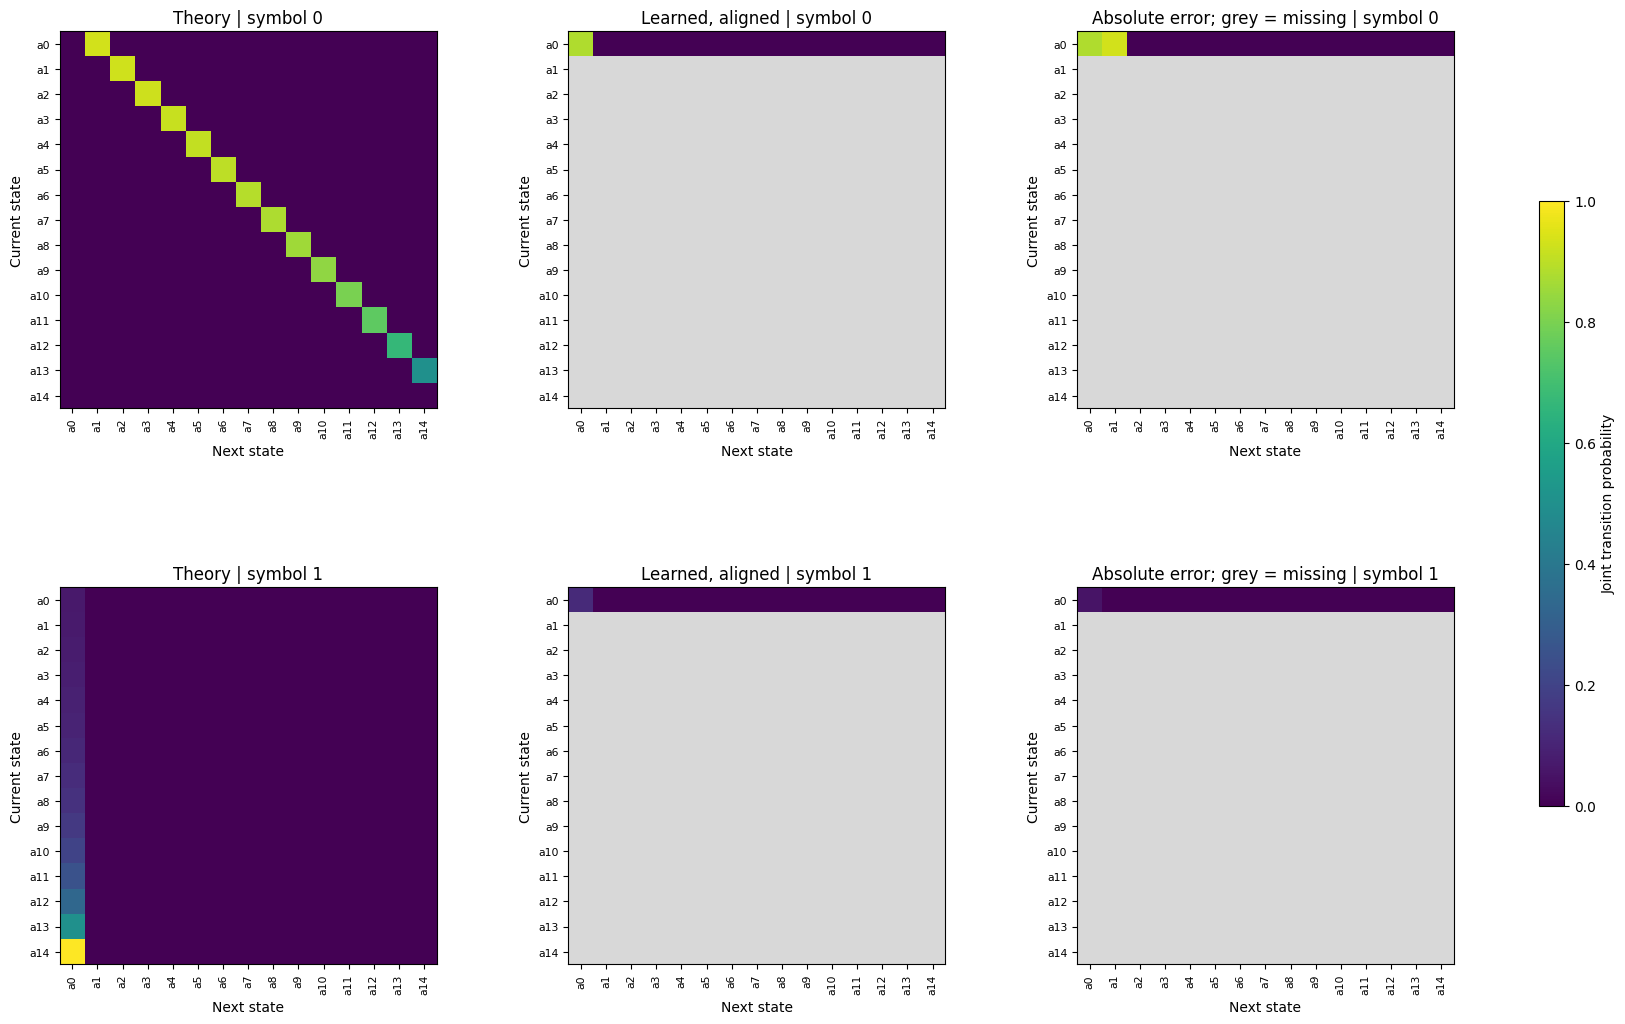

,theory_age,learned_state,raw_codes,alignment_purity,theory_P1,learned_P1,theory_next0,learned_next0,theory_next1,learned_next1
0,0,R0,[1],0.12975,0.06667,0.11784,a1,R0 / a0,a0,R0 / a0
1,1,MISSING,[],NaN,0.07143,NaN,a2,MISSING,a0,MISSING
2,2,MISSING,[],NaN,0.07692,NaN,a3,MISSING,a0,MISSING
3,3,MISSING,[],NaN,0.08333,NaN,a4,MISSING,a0,MISSING
4,4,MISSING,[],NaN,0.09091,NaN,a5,MISSING,a0,MISSING
5,5,MISSING,[],NaN,0.10000,NaN,a6,MISSING,a0,MISSING
6,6,MISSING,[],NaN,0.11111,NaN,a7,MISSING,a0,MISSING
7,7,MISSING,[],NaN,0.12500,NaN,a8,MISSING,a0,MISSING
8,8,MISSING,[],NaN,0.14286,NaN,a9,MISSING,a0,MISSING
9,9,MISSING,[],NaN,0.16667,NaN,a10,MISSING,a0,MISSING


Theory-weighted joint-transition TV (missing states count as 1): 0.991667


In [20]:
aligned_theory=np.zeros((axis_size,axis_size,2))
aligned_theory[:15,:15]=theory_M
aligned_learned=np.zeros_like(aligned_theory)
for r in range(N_min):
    for s in range(N_min):
        aligned_learned[minimal_to_axis[r],minimal_to_axis[s]]=learned_minimal["M"][r,s]
for a in missing_ages:aligned_learned[a,:,:]=np.nan

fig,axes=plt.subplots(2,3,figsize=(17,11))
cmap=plt.get_cmap("viridis").copy();cmap.set_bad("#D8D8D8")
for x in range(2):
    matrices=[aligned_theory[:,:,x],aligned_learned[:,:,x],np.abs(aligned_learned[:,:,x]-aligned_theory[:,:,x])]
    for col,(matrix,title) in enumerate(zip(matrices,["Theory","Learned, aligned","Absolute error; grey = missing"])):
        ax=axes[x,col]
        im=ax.imshow(matrix,vmin=0,vmax=1,cmap=cmap)
        ax.set(title=f"{title} | symbol {x}",xlabel="Next state",ylabel="Current state",
                xticks=range(axis_size),yticks=range(axis_size),xticklabels=axis_labels,yticklabels=axis_labels)
        ax.tick_params(labelsize=max(5,9-axis_size*.08))
        plt.setp(ax.get_xticklabels(),rotation=90)
        if extras:
            ax.axhline(14.5,color="white",linestyle="--",linewidth=.7)
            ax.axvline(14.5,color="white",linestyle="--",linewidth=.7)
fig.subplots_adjust(left=.06,right=.88,bottom=.07,top=.95,wspace=.35,hspace=.35)
colorbar_axis=fig.add_axes([.93,.23,.015,.55])
fig.colorbar(im,cax=colorbar_axis,label="Joint transition probability")
fig.savefig(RUN_DIR/"symbol_transitions.png",dpi=180,bbox_inches="tight")
fig.savefig(RUN_DIR/"symbol_transitions.pdf",bbox_inches="tight")
plt.show()

def destination_name(r,x):
    row=learned_minimal["M"][r,:,x]
    if row.sum()==0:return "undefined"
    s=int(row.argmax())
    return f"R{s} / a{minimal_to_age[s]}" if s in minimal_to_age else f"R{s} / extra"

transition_rows=[]
for age in range(15):
    r=age_to_minimal.get(age)
    emission=learned_minimal["M"][r].sum(axis=0) if r is not None else [np.nan,np.nan]
    count=alignment_counts[r].sum() if r is not None else 0
    transition_rows.append(dict(theory_age=age,learned_state=f"R{r}" if r is not None else "MISSING",
                                raw_codes=learned_minimal["groups"][r] if r is not None else [],
                                alignment_purity=float(alignment_counts[r,age]/count) if count else np.nan,
                                theory_P1=theory_emission[age,1],learned_P1=emission[1],
                                theory_next0=f"a{age+1}" if age<14 else "undefined (P0=0)",
                                learned_next0=destination_name(r,0) if r is not None else "MISSING",
                                theory_next1="a0",learned_next1=destination_name(r,1) if r is not None else "MISSING"))
transition_table=pd.DataFrame(transition_rows)
display(transition_table.round(5))
transition_table.to_csv(RUN_DIR/"transition_comparison.csv",index=False)

# Penalize missing theory rows explicitly in a theory-occupancy-weighted comparison.
# Missing row penalty=1 (maximum total variation); extra destinations are included.
row_tv=[]
for age in range(15):
    if age not in age_to_minimal:row_tv.append(1.0)
    else:row_tv.append(float(.5*np.abs(aligned_learned[age]-aligned_theory[age]).sum()))
test_metrics["theory_weighted_transition_TV_missing_penalty_1"]=float(theory_pi@np.array(row_tv))
print("Theory-weighted joint-transition TV (missing states count as 1):",
      round(test_metrics["theory_weighted_transition_TV_missing_penalty_1"],6))

### Emission probabilities, final L2 by rollout position, and saved results

Emission differences can be small even when transition rules are wrong. Read the emission plot
together with the state-correspondence heatmap and symbol-labelled matrices. The second panel
shows exactly the requested full-vector L2 averaged across held-out sequences at each continuation
position, comparing both branches after the same observation.

All machine arrays, assignments, metrics, tables, plots, and the final checkpoint are saved beside
the run histories. The raw extracted machine is kept in addition to its minimized recurrent part.
No approximate state merging, best-checkpoint restoration, or theory-supervised training is applied.

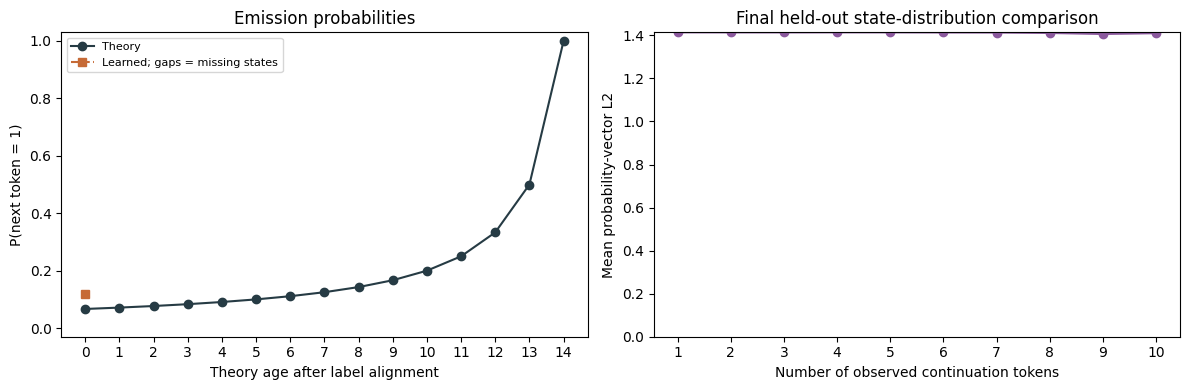

Extraction, alignment, and L2 reduction checks passed.
Completed updates: 30,000
Final test excess CE: 0.032548 bits/token
Final probability L2: 1.412485
Theory states / learned minimal recurrent states: 15 / 1
Saved all results to: /Users/tisornnaphattalung/Desktop/Quantum/URECA/LLM_final_version/model_modeularised/notebook_results/renewal15_a17406823119


In [21]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(range(15),theory_emission[:,1],"o-",color="#263B44",label="Theory")
learned_p1=transition_table.learned_P1.to_numpy()
axes[0].plot(range(15),learned_p1,"s--",color="#C66A36",label="Learned; gaps = missing states")
axes[0].set(xlabel="Theory age after label alignment",ylabel="P(next token = 1)",
            title="Emission probabilities",xticks=range(15),ylim=(-.03,1.03))
axes[0].legend(fontsize=8)
l2_by_position=torch.linalg.vector_norm(test_result["qT"]-test_result["qG"],dim=-1).mean(dim=0).numpy()
axes[1].plot(np.arange(1,L+1),l2_by_position,"o-",color="#8C5A9E")
axes[1].set(xlabel="Number of observed continuation tokens",ylabel="Mean probability-vector L2",
            title="Final held-out state-distribution comparison",xticks=range(1,L+1),ylim=(0,math.sqrt(2)))
fig.tight_layout()
fig.savefig(RUN_DIR/"emissions_and_final_l2.png",dpi=180,bbox_inches="tight")
plt.show()

np.savez_compressed(RUN_DIR/"machine_arrays.npz",theory_M=theory_M,theory_T=theory_T,
                    theory_emission=theory_emission,theory_pi=theory_pi,
                    learned_raw_M=learned_raw["M"],learned_raw_delta=learned_raw["delta"],
                    learned_raw_emission=learned_raw["emission"],
                    learned_recurrent_minimal_M=learned_minimal["M"],
                    raw_to_minimal=learned_minimal["raw_to_minimal"],
                    aligned_theory=aligned_theory,aligned_learned=aligned_learned,
                    alignment_counts=alignment_counts,test_counts=test_counts,l2_by_position=l2_by_position)
(RUN_DIR/"metrics.json").write_text(json.dumps(test_metrics,indent=2))
(RUN_DIR/"state_alignment.json").write_text(json.dumps(dict(minimal_to_age=minimal_to_age,
                    raw_groups=learned_minimal["groups"],components=learned_minimal["components"],
                    reachable_raw=learned_minimal["reachable"].tolist(),missing_ages=missing_ages,
                    extra_recurrent_states=extras),indent=2))

# Audit the final arrays: normalized rows, genuine missing markers, and exact recorded L2 reduction.
assert np.allclose(learned_raw["M"].sum(axis=(1,2)),1)
assert np.allclose(learned_minimal["M"].sum(axis=(1,2)),1)
assert np.isclose(l2_by_position.mean(),test_result["mean_l2"],atol=1e-6)
assert len(set(minimal_to_age.values()))==len(minimal_to_age)
assert np.allclose(test_counts.sum(axis=1),np.bincount(test_age.ravel(),minlength=15))
assert np.allclose(aligned_learned[np.isfinite(aligned_learned).all(axis=(1,2))].sum(axis=(1,2)),1)
print("Extraction, alignment, and L2 reduction checks passed.")
print("Completed updates:",f"{renewal15_run['updates']:,}")
print("Final test excess CE:",round(test_metrics["excess_test_ce_bits"],6),"bits/token")
print("Final probability L2:",round(test_metrics["mean_probability_l2"],6))
print("Theory states / learned minimal recurrent states:",15,"/",N_min)
print("Saved all results to:",RUN_DIR)

### How to read this experiment

1. **Prediction:** compare held-out CE with exact CE on those same tokens. The training loss alone
   cannot tell you whether the deterministic evaluation machine is correct.
2. **Transformer–GRU consistency:** inspect the L2 curve and its final per-position values. CE-only
   training supplies no direct constraint forcing these two probability vectors to agree.
3. **State discovery:** inspect missing/extra states and the held-out correspondence heatmap.
   Equal numbers of states would not establish an isomorphism.
4. **Dynamics:** compare both symbol-labelled transition matrices and the successor table. An
   epsilon-machine match requires the correct emission weights and transitions after a valid relabelling.

The displayed results are one seeded training run with the declared update budget, including any
failure to recover the theory. The notebook does not silently tune the architecture, add a state loss,
or choose a more favorable checkpoint to make the machine diagram match.

### Observed result of the completed run

The 30,000-update run (seed 17) completed in 10.79 minutes on CPU.
Final held-out CE was **0.518629 bits/token**, against exact CE **0.486081**
on the same tokens: an excess of **0.032548 bits/token**.
The final mean full-probability L2 was **1.412485**, close to its upper bound sqrt(2).

This run **did not recover the theoretical 15-state epsilon-machine**. It used nine predictive codes;
eight are transient, and one is recurrent. Every reachable state's symbol-1 transition leads to **L1**.
L1 then loops to itself on both 0 and 1, emitting 1 with probability 0.117841. It accounts for 87.16%
of the scored test positions. Consequently the GRU loses renewal-age information after entering L1.
The Transformer starts in transient codes, so some short-window predictions benefit from the initial
history mapping before the rollout reaches that absorbing code.

The recurrent code's assignment to a0 in the comparison is just the maximum-overlap relabelling;
its alignment purity is only 12.98%, so it should not be read as successful recovery of age 0.
The raw graph and table expose the transient behavior; the recurrent graph exposes the long-run
failure. These are the actual final parameters from this declared run, with no state-alignment loss
or favorable checkpoint selection.

To repeat or change the experiment, edit `EXPERIMENT` / `renewal15_cfg` in the full-run cell.
An unchanged configuration loads the saved result. Set `FORCE_RETRAIN=True` only when you want to
repeat all 30,000 optimizer updates. The earlier small tutorial remains available in sections 1–12.


## 14. Renewal with nine causal states: controlled comparisons

This section uses `HMM_processes.PROCESS["renewal"]` with gap distribution
`F = [.04, .08, .12, .16, .20, .16, .12, .08, .04]`, matching the nine-state
renewal examples elsewhere in this folder. Age means the number of zeros since the most recent 1.
There are nine theoretical causal states. Every history has 20 tokens, which is enough to
synchronize this bounded-gap process.

We test five configurations, all with seed 17, 30,000 Adam updates, learning rate 0.001,
16 available states, state-vector width 32, zero weight decay, and **only continuation CE**.
The hybrid has four Transformer layers of width 16. Every update scores 1,280 future tokens;
each run therefore scores 38.4 million tokens. Fresh sequences are generated each update.
This is one seed per configuration, a diagnostic comparison rather than evidence of a universal ranking.

| Configuration | Change and motivation |
|---|---|
| Hybrid baseline | H=20, L=10, batch=128; shared temperature 2.25 → 0.1 |
| Longer continuation | L=40, batch=32: stresses the learned recurrence while keeping the number of scored tokens fixed; fewer independent initial histories and more correlated targets |
| Learned input vectors | Makes the initially identical frozen token vectors trainable, following the option in `Transformer.py` |
| Warmer final temperature | 2.25 → 0.5; inspired by the 0.5 endpoints in `run_model.py`; all other baseline settings unchanged |
| Existing feedback GRU | Uses `GRU.DiscreteFeedbackGRU` directly; it consumes the 20 history tokens recurrently before the same scored suffix |

The comparison runner in `checks/notebook_hybrid_experiments.py` reads the model definitions
from this notebook without executing its training cells. It never imports your unfinished
`hybrid_transformer_GRU_v2.py`. Its saved configuration includes a hash of those definitions.
Unchanged configurations load the completed runs; a missing run is trained in full.
The architecture code remains visible in the earlier teaching cells.

In [22]:
from checks import notebook_hybrid_experiments as experiment9

torch.set_num_threads(2)
RESULTS9 = MODULE_DIR / "notebook_results" / "renewal9_comparison"
RESULTS9.mkdir(parents=True, exist_ok=True)
configs9 = {name: experiment9.settings(name) for name in experiment9.TRIALS}
models9, runs9 = {}, {}
for name, config in configs9.items():
    models9[name], runs9[name] = experiment9.train_trial(config)
    assert runs9[name]["updates"] == 30_000
    print(f"{config['label']}: {runs9[name]['updates']:,} updates; "
          f"{runs9[name]['seconds']/60:.1f} training minutes; {experiment9.result_dir(config).name}")
assert all(c["batch_size"]*c["rollout_len"]*c["steps"] == 38_400_000 for c in configs9.values())
display(pd.DataFrame([dict(name=c["label"], history=c["history_len"], rollout=c["rollout_len"],
                          batch=c["batch_size"], final_temperature=c["tau_end"],
                          trainable_parameters=sum(p.numel() for p in models9[n].parameters()))
                     for n,c in configs9.items()]))

Hybrid baseline: 30,000 updates; 9.8 training minutes; baseline_s17_74d47475f4
Hybrid: rollout 40: 30,000 updates; 9.9 training minutes; long_rollout_s17_94d99a6586


Hybrid: learned input: 30,000 updates; 10.2 training minutes; learned_input_s17_393b330cce
Hybrid: final tau 0.5: 30,000 updates; 9.8 training minutes; warmer_tau_s17_8ca37a33f7


Existing feedback GRU: 30,000 updates; 6.5 training minutes; feedback_gru_s17_7c8d159cbb


,name,history,rollout,batch,final_temperature,trainable_parameters
0,Hybrid baseline,20,10,128,0.1,16866
1,Hybrid: rollout 40,20,40,32,0.1,16866
2,Hybrid: learned input,20,10,128,0.1,16898
3,Hybrid: final tau 0.5,20,10,128,0.5,16866
4,Existing feedback GRU,20,10,128,0.1,4562


### Learning curves and the meaning of L2

All validation CE curves score exactly the same 512 independent 20+10-token windows, even
when training used a 40-token continuation. The dashed line is the likelihood under the
true process on those same validation tokens. Training CE includes Gumbel sampling;
validation selects states deterministically by argmax.

The state diagnostic compares the **full selection vectors over the same learned codebook**.
After each observed continuation token, one vector comes from the Transformer reading the entire
prefix, and the other from updating the previous selected GRU state with that token:

$$D(\tau)=\frac{1}{BL}\sum_{b,k}\sqrt{\sum_{s=1}^{K}
[q^{\rm TF}_{b,k}(s;\tau)-q^{\rm GRU}_{b,k}(s;\tau)]^2}.$$

Here both paths have seen the same observations. Evaluation uses no Gumbel noise.
A distance of zero means identical vectors; its maximum is $\sqrt{2}$, reached by different
one-hot vectors. Two initially uniform vectors also have distance zero: low L2 alone does
not demonstrate causal-state recovery. The metric does **not** compare with the theoretical
state labels and is never included in the loss.

We plot both the scheduled-temperature L2 and **L2 recomputed at fixed temperature 1**.
The latter removes the changing temperature from this diagnostic, although learned logits can
still become sharper. Neither curve is invariant to state relabelling: both paths intentionally
share the same codebook, so this comparison asks whether they use its slots consistently.
The Transformer is trained to initialize the rollout after 20 tokens; its outputs on the longer
prefixes used in this diagnostic receive no direct consistency supervision.

Changing the temperature of a fixed set of logits does not change argmax. With fixed Gumbel noise,
it does not change the hard sampled choice either; it changes the soft relaxation and its gradients.
Therefore a different temperature schedule can change the eventual fitted model.

**Indexing audit: no one-token shift.** For H=20 and L=10, initialization reads tokens
$x_0,\ldots,x_{19}$. The first comparison uses the Transformer output at position 20
(prefix through $x_{20}$) and the GRU state after consuming $x_{20}$. The last comparison
uses the prefix through $x_{29}$ and the GRU state after consuming $x_{29}$.
Prediction CE instead scores $x_j$ using the state *before* consuming $x_j$.
The diagnostic therefore includes a terminal update after the final scored prediction;
that terminal update receives no loss in that window.

The audit in `checks/check_notebook_diagnostic_alignment.py` checks the actual notebook
function against separate prefix evaluations and explicit GRU transitions. It passed for the
trained renewal-15 model and all four renewal-9 hybrids, with zero maximum difference in
Transformer probabilities on the checked prefixes. For renewal-15's 512 validation rows,
both reductions gave D=1.412337. An exact counter-machine control gave D=0 with the current
indexing and D=1.414214 after a deliberately introduced one-token shift.
Results are saved in `notebook_results/renewal9_comparison/diagnostic_alignment_audit.json`.


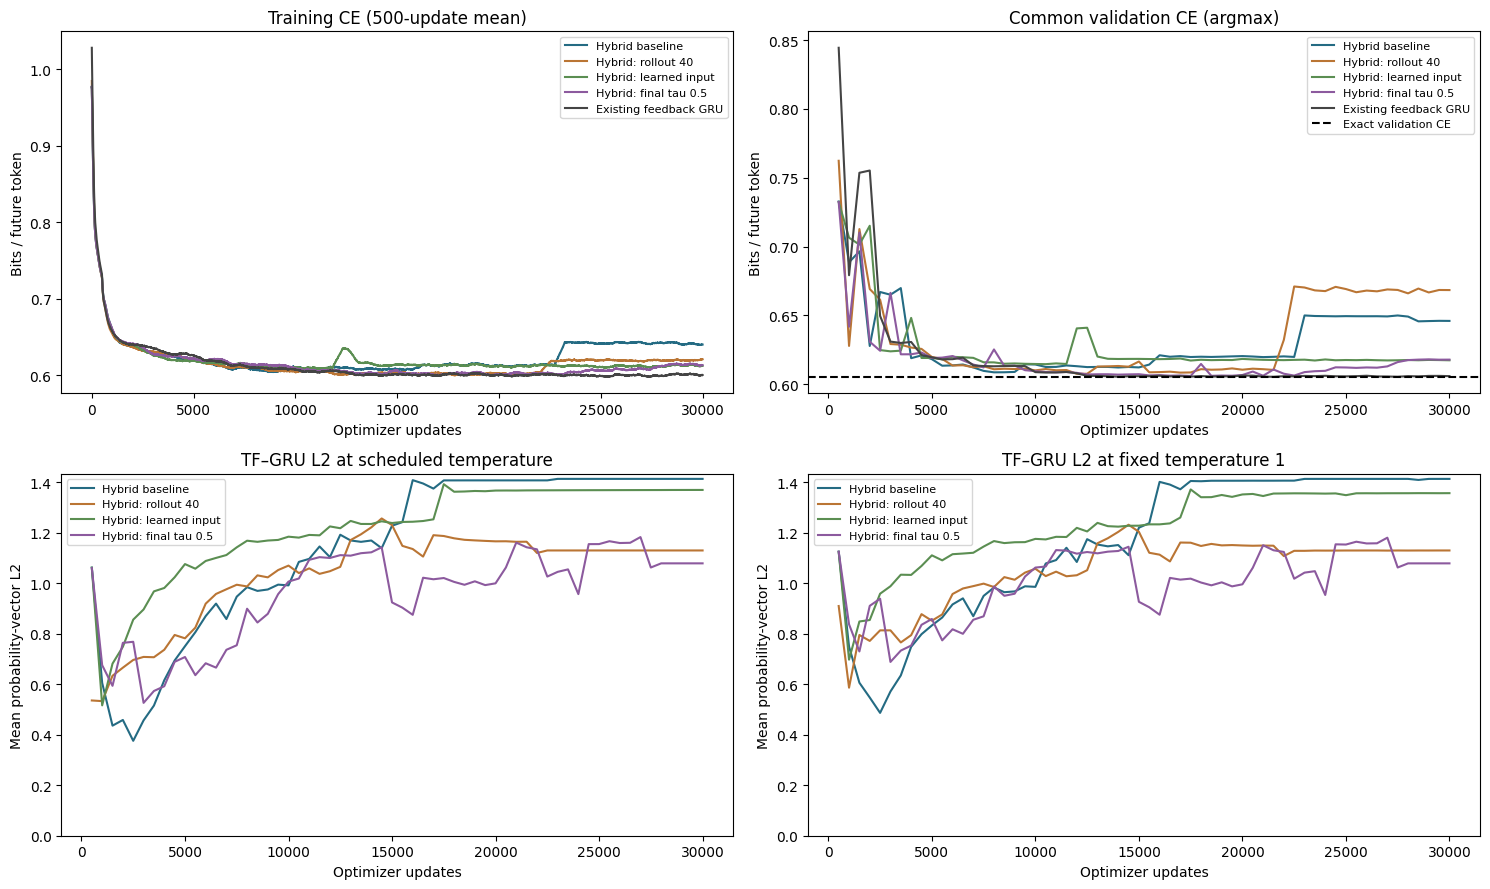

Hybrid highlighted by final validation CE: Hybrid: learned input


In [23]:
colors9 = dict(zip(configs9, ["#246B83", "#BA7534", "#5B8E52", "#8C5A9E", "#444444"]))
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for name, config in configs9.items():
    train = pd.DataFrame(runs9[name]["training"])
    val = pd.DataFrame(runs9[name]["validation"])
    color, label = colors9[name], config["label"]
    axes[0,0].plot(train["update"], train.ce_bits.rolling(500,min_periods=1).mean(),color=color,label=label)
    axes[0,1].plot(val["update"], val.ce_bits,color=color,label=label)
    if config["kind"] == "hybrid":
        axes[1,0].plot(val["update"],val.mean_l2,color=color,label=label)
        axes[1,1].plot(val["update"],val.fixed_tau1_l2,color=color,label=label)
axes[0,1].axhline(val.exact_ce_bits.iloc[-1],color="black",ls="--",label="Exact validation CE")
for ax,title in zip(axes.flat,["Training CE (500-update mean)","Common validation CE (argmax)",
                              "TF–GRU L2 at scheduled temperature","TF–GRU L2 at fixed temperature 1"]):
    ax.set(title=title,xlabel="Optimizer updates")
    ax.legend(fontsize=8)
for ax in axes[0]: ax.set_ylabel("Bits / future token")
for ax in axes[1]: ax.set(ylabel="Mean probability-vector L2",ylim=(0,math.sqrt(2)+.02))
fig.tight_layout()
fig.savefig(RESULTS9/"training_comparison.png",dpi=180,bbox_inches="tight")
fig.savefig(RESULTS9/"training_comparison.pdf",bbox_inches="tight")
plt.show()
# Choose a highlighted hybrid using final validation CE only, before examining test results.
best_hybrid9 = min((n for n,c in configs9.items() if c["kind"]=="hybrid"),
                  key=lambda n:runs9[n]["validation"][-1]["ce_bits"])
print("Hybrid highlighted by final validation CE:",configs9[best_hybrid9]["label"])

### Evaluate held-out predictions and extract the actual machines

Alignment, final testing, and long-continuation testing use independent random seeds.
All models see the same 4,096 test windows and the same 1,024 long windows with 200 future tokens.
The long test gives the model only one initialization and then no resets.

We enumerate every `(learned code, observed symbol)` to recover its exact deterministic successor
and its symbol probabilities. The recurrent diagram discards transient states and merges only
numerically identical predictive states (tolerance 1e-10). We also retain the raw reachable diagram.
A Hungarian assignment on the separate alignment data maps recurrent states to theoretical ages;
missing ages and unmatched extra states are retained explicitly. A label match is not assumed to
prove causal-state equivalence.

In [24]:
alignment9_tokens, alignment9_states = experiment9.Sampler(7303).draw(4096,30,states=True)
test9_tokens, test9_states = experiment9.Sampler(8404).draw(4096,30,states=True)
long9_tokens, long9_states = experiment9.Sampler(9505).draw(1024,220,states=True)
analysis9 = {}
summary9_rows = []
for name, config in configs9.items():
    model = models9[name]
    model.eval()
    ec = dict(config,tau_eval=config["tau_end"])
    raw = experiment9.raw_machine(model,config["kind"])
    alignment = experiment9.evaluate(model,ec,alignment9_tokens,alignment9_states,l2=False,keep_arrays=True)
    test = experiment9.evaluate(model,ec,test9_tokens,test9_states,keep_arrays=True)
    long_test = experiment9.evaluate(model,ec,long9_tokens,long9_states,l2=False,keep_arrays=True)
    minimal = recurrent_minimal_machine(raw,alignment["starts"])
    size = len(minimal["M"])
    ids = minimal["raw_to_minimal"][alignment["states"]]
    counts = np.zeros((size,9),dtype=int)
    valid = ids>=0
    np.add.at(counts,(ids[valid],alignment["ages"][valid]),1)
    rows,cols = linear_sum_assignment(-counts)
    mapping = {int(r):int(c) for r,c in zip(rows,cols) if counts[r,c]>0}
    test_min = minimal["raw_to_minimal"][test["states"]]
    predicted_age = np.full(test_min.shape,-1)
    for r,a in mapping.items(): predicted_age[test_min==r]=a
    reached = minimal["reachable"]
    initial = np.bincount(alignment["starts"],minlength=16)[reached]
    pi_reached = stationary_from_initial(raw["M"][np.ix_(reached,reached)],initial)
    pi_raw = np.zeros(16); pi_raw[reached]=pi_reached
    pi_min = np.array([pi_raw[g].sum() for g in minimal["groups"]])
    extras = [r for r in range(size) if r not in mapping]
    axes_for_state = dict(mapping)
    axes_for_state.update({r:9+k for k,r in enumerate(extras)})
    axis_labels = [f"a{a}" for a in range(9)]+[f"extra R{r}" for r in extras]
    # Keep missing rows as NaN rather than claiming a learned zero-probability state.
    aligned = np.full((len(axis_labels),len(axis_labels),2),np.nan)
    for r in range(size):
        ar = axes_for_state[r]; aligned[ar]=0
        for s in range(size): aligned[ar,axes_for_state[s]]+=minimal["M"][r,s]
    theory_aligned = np.zeros_like(aligned)
    theory_aligned[:9,:9]=experiment9.M
    tv = np.ones(9)
    for a in range(9):
        if np.isfinite(aligned[a]).all(): tv[a]=.5*np.abs(aligned[a]-theory_aligned[a]).sum()
    row = dict(name=name,label=config["label"],test_ce_bits=test["ce_bits"],
               exact_test_ce_bits=test["exact_ce_bits"],test_excess_bits=test["excess_ce_bits"],
               long_excess_bits=long_test["excess_ce_bits"],mean_l2=test["mean_l2"],
               fixed_tau1_l2=test["fixed_tau1_l2"],reachable_codes=len(reached),
               minimal_recurrent_states=size,closed_classes=minimal["n_closed_classes"],
               aligned_state_accuracy=float((predicted_age==test["ages"]).mean()),
               transient_fraction=float((test_min<0).mean()),
               transition_TV=float(experiment9.PI@tv))
    summary9_rows.append(row)
    analysis9[name] = dict(raw=raw,minimal=minimal,alignment=alignment,test=test,long_test=long_test,
                          mapping=mapping,pi_raw=pi_raw,pi_min=pi_min,aligned=aligned,
                          aligned_theory=theory_aligned,axis_labels=axis_labels,counts=counts)
    assert np.allclose(raw["M"].sum(axis=(1,2)),1,atol=1e-6)
    assert len(set(mapping.values()))==len(mapping)
    assert set(test["starts"]).issubset(set(reached))
    np.savez_compressed(RESULTS9/f"{name}_machines.npz",raw_M=raw["M"],raw_delta=raw["delta"],
                        raw_emission=raw["emission"],minimal_M=minimal["M"],aligned_M=aligned,
                        theory_M=experiment9.M,raw_to_minimal=minimal["raw_to_minimal"],
                        alignment_counts=counts)
summary9 = pd.DataFrame(summary9_rows).set_index("name")
summary9.to_csv(RESULTS9/"summary.csv")
display(summary9.round(6))
print("TV compares aligned joint (next state, symbol) rows, weighted by theory stationary occupancy;")
print("missing theory rows get TV=1. Extra learned states remain explicit in the matrices.")

,label,test_ce_bits,exact_test_ce_bits,test_excess_bits,long_excess_bits,mean_l2,fixed_tau1_l2,reachable_codes,minimal_recurrent_states,closed_classes,aligned_state_accuracy,transient_fraction,transition_TV
name,,,,,,,,,,,,,
baseline,Hybrid baseline,0.640122,0.599948,0.040174,0.015021,1.414213,1.414168,9,7,1,0.681665,0.179980,0.067237
long_rollout,Hybrid: rollout 40,0.671016,0.599948,0.071068,0.004920,1.130611,1.130579,9,9,1,0.761279,0.000000,0.011710
learned_input,Hybrid: learned input,0.611894,0.599948,0.011946,0.005463,1.367132,1.355827,10,8,1,0.721973,0.069263,0.025403
warmer_tau,Hybrid: final tau 0.5,0.613093,0.599948,0.013146,0.003059,1.075658,1.075619,9,9,1,0.832446,0.000000,0.009030
feedback_gru,Existing feedback GRU,0.599979,0.599948,0.000031,0.000182,NaN,NaN,9,9,1,1.000000,0.000000,0.003986


TV compares aligned joint (next state, symbol) rows, weighted by theory stationary occupancy;
missing theory rows get TV=1. Extra learned states remain explicit in the matrices.


### Epsilon-machine drawings in the existing project style

These plots call **`plotting._draw_machine`**, the same renderer used by the folder's
`plot_machine_graph`: blue nodes, stationary weights π, grey arrows, and `symbol|probability`
edge labels. Self-loop labels appear inside the nodes. As in the existing plotting code,
edges with probability at most 0.01 are hidden visually; extraction and tables retain them.

`Rk → aj` means recurrent learned state Rk was matched to theory age aj using the alignment data.
It does not mean that the match is accurate. Raw labels `Lk` identify actual codebook entries;
`rec` and `trans` distinguish recurrent and transient states. π is long-run generated occupancy,
which can differ markedly from occupancy during ten-token, teacher-forced continuations.

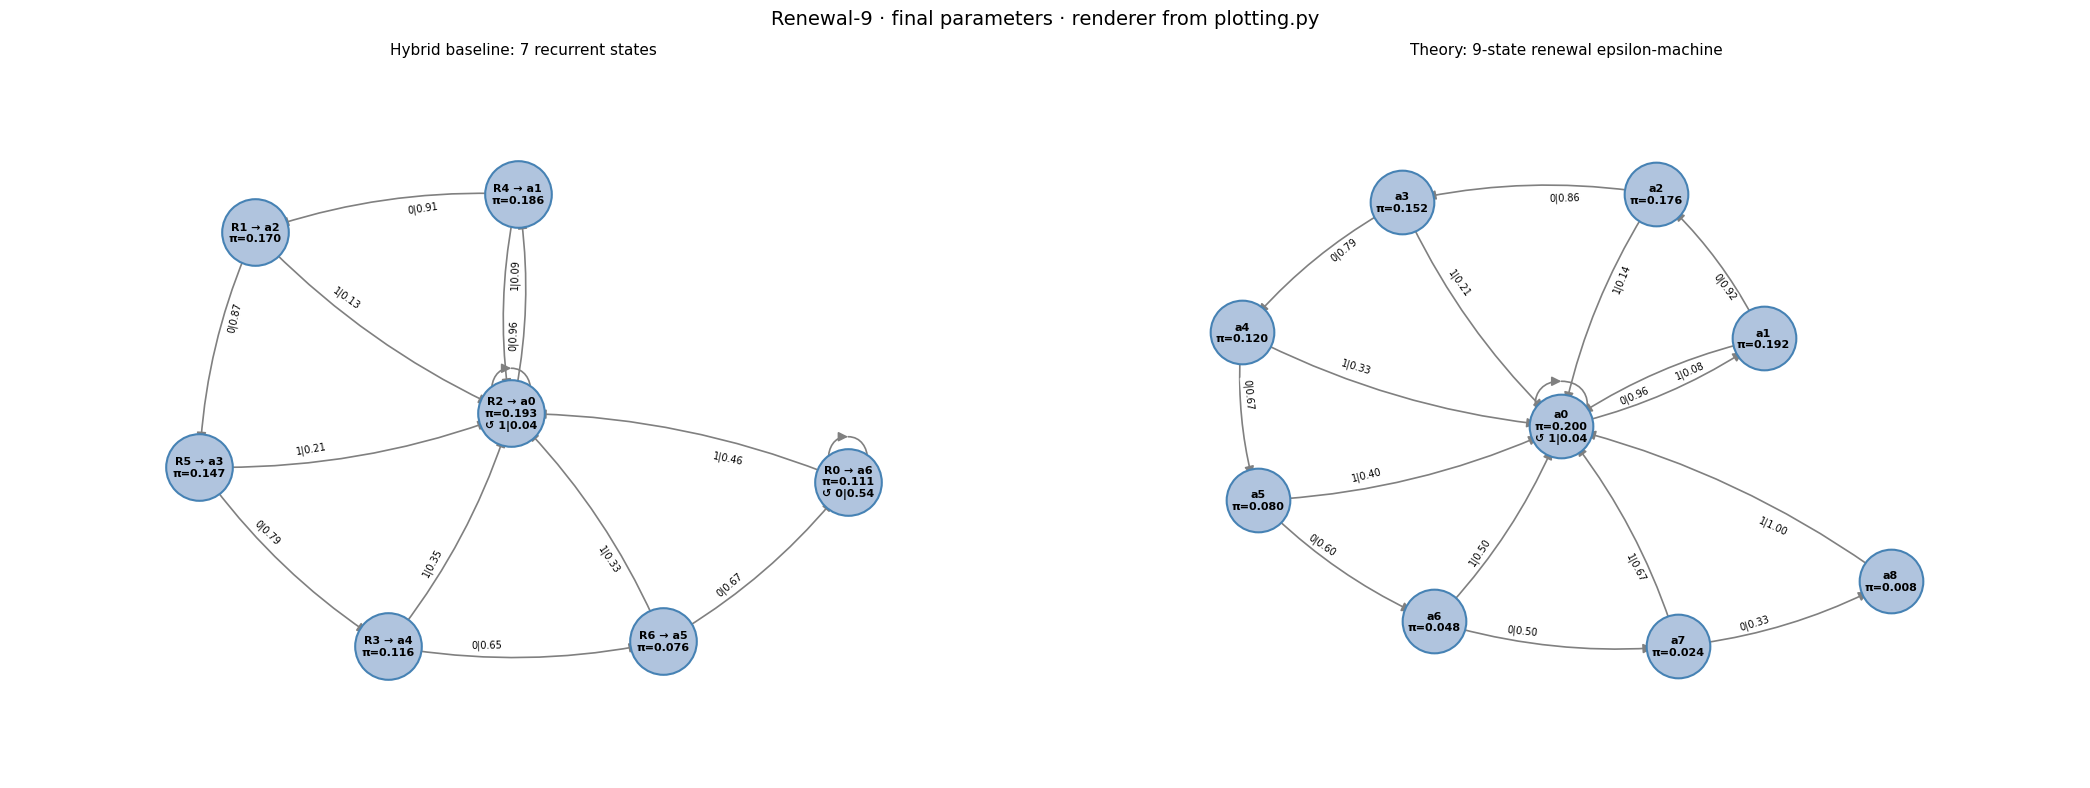

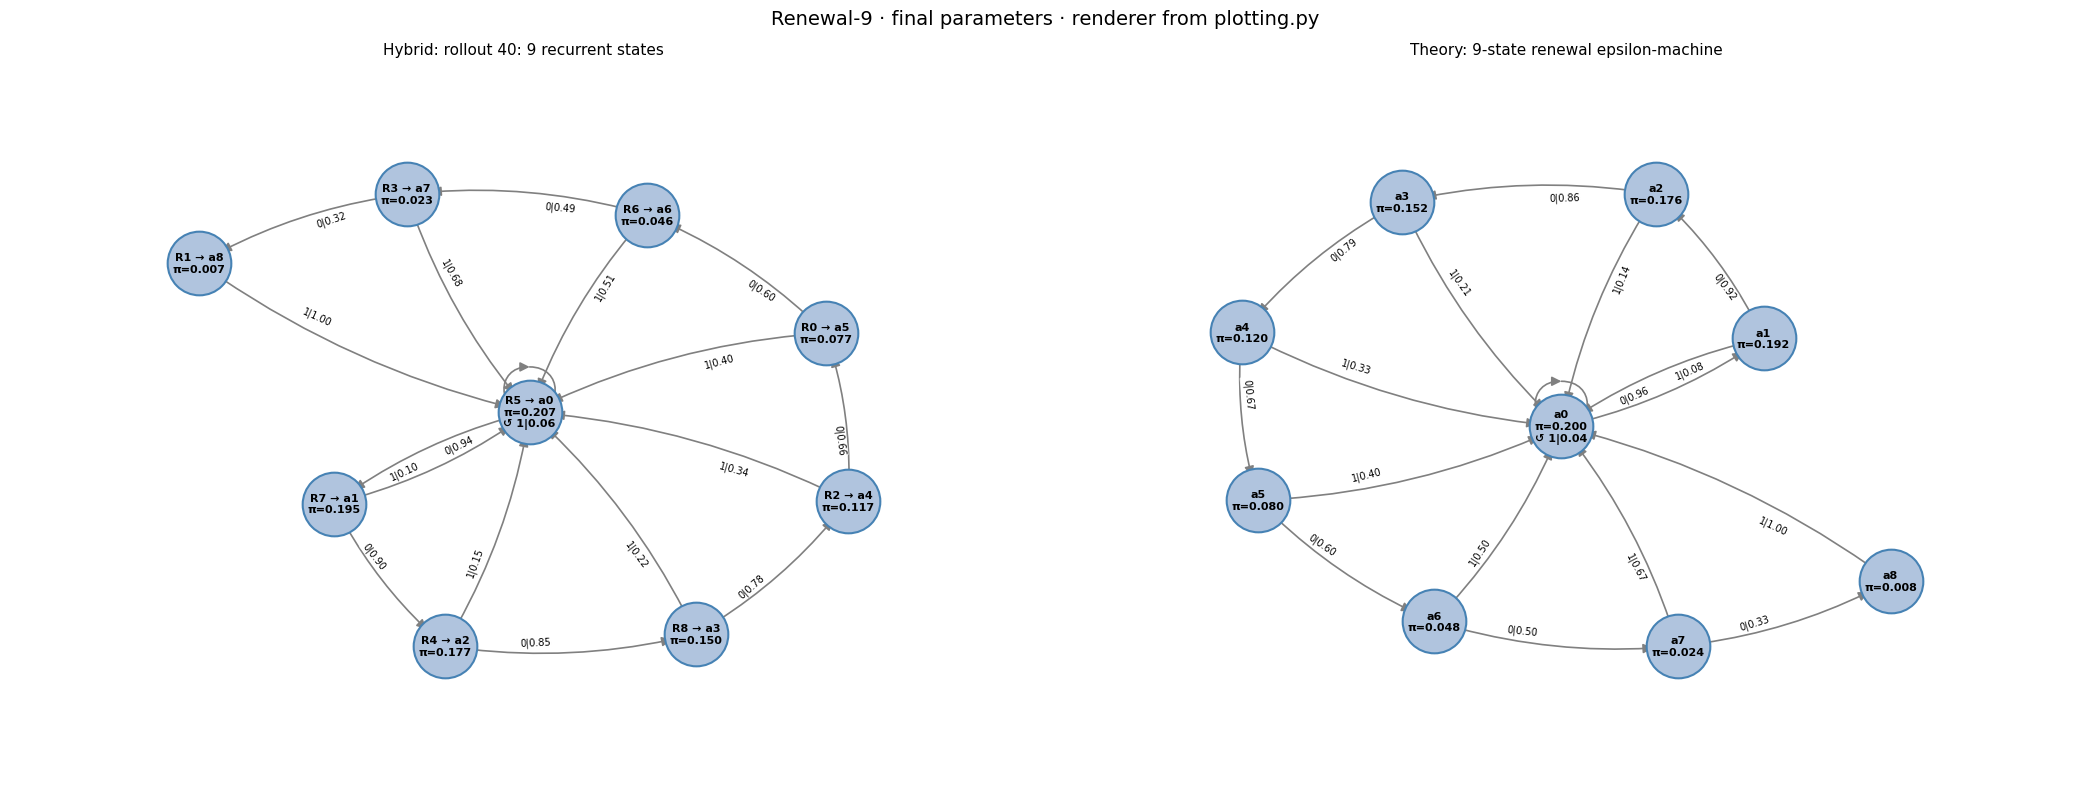

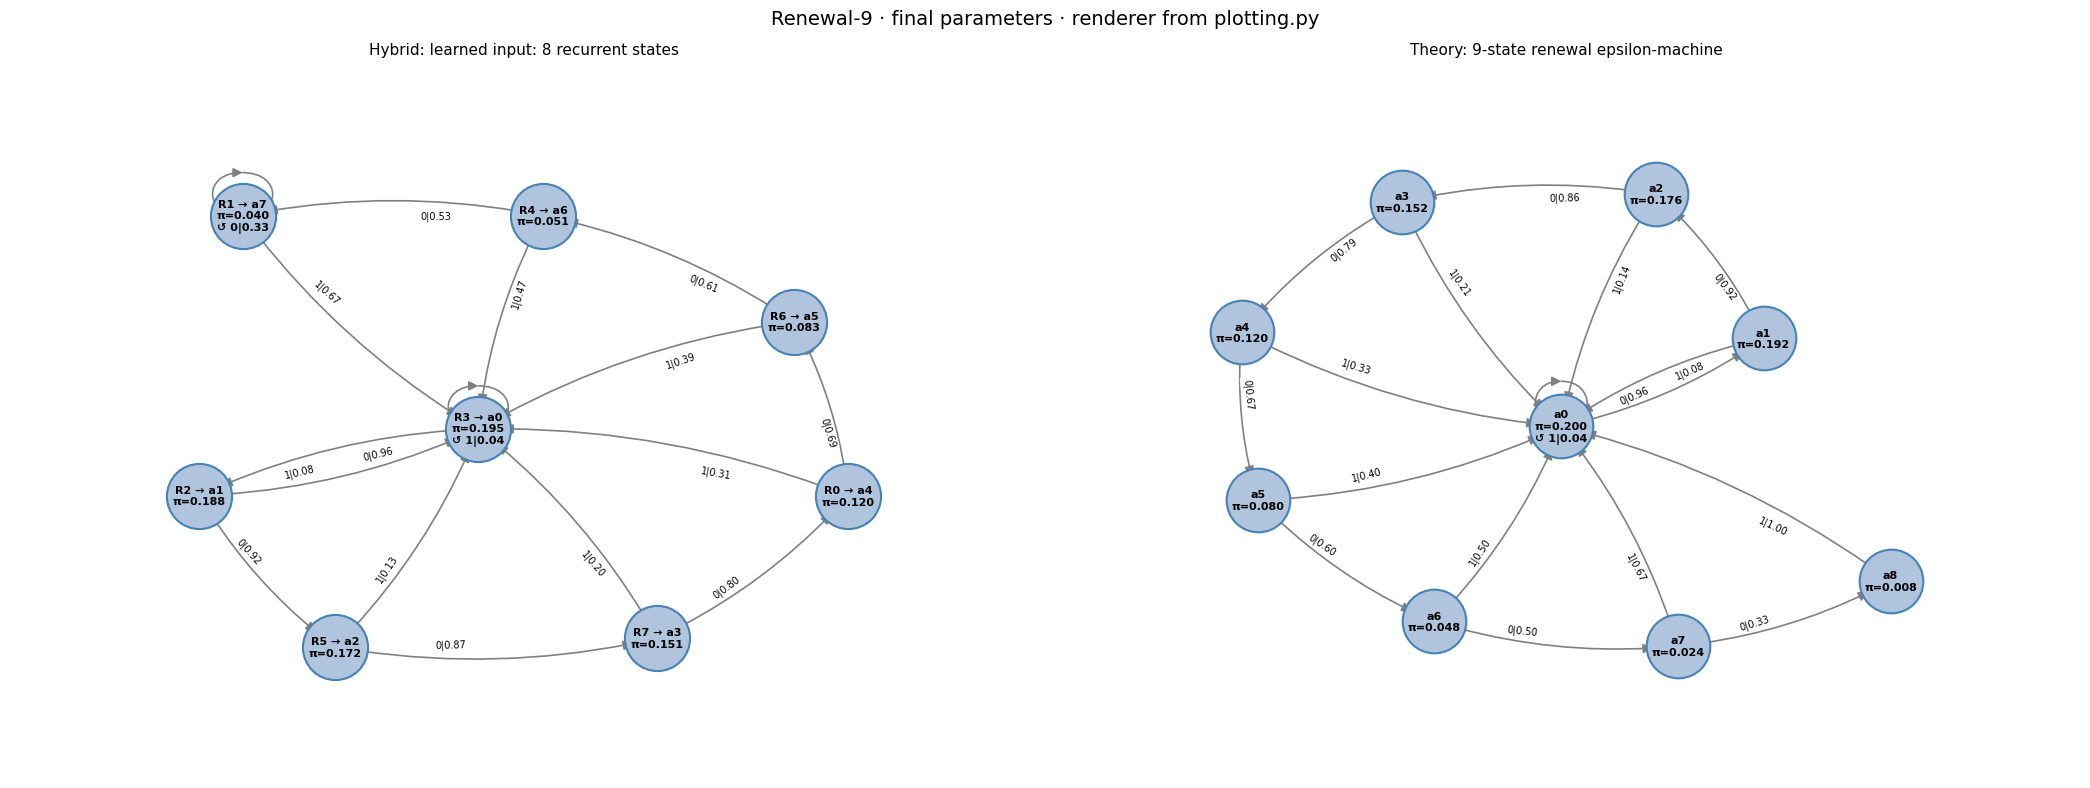

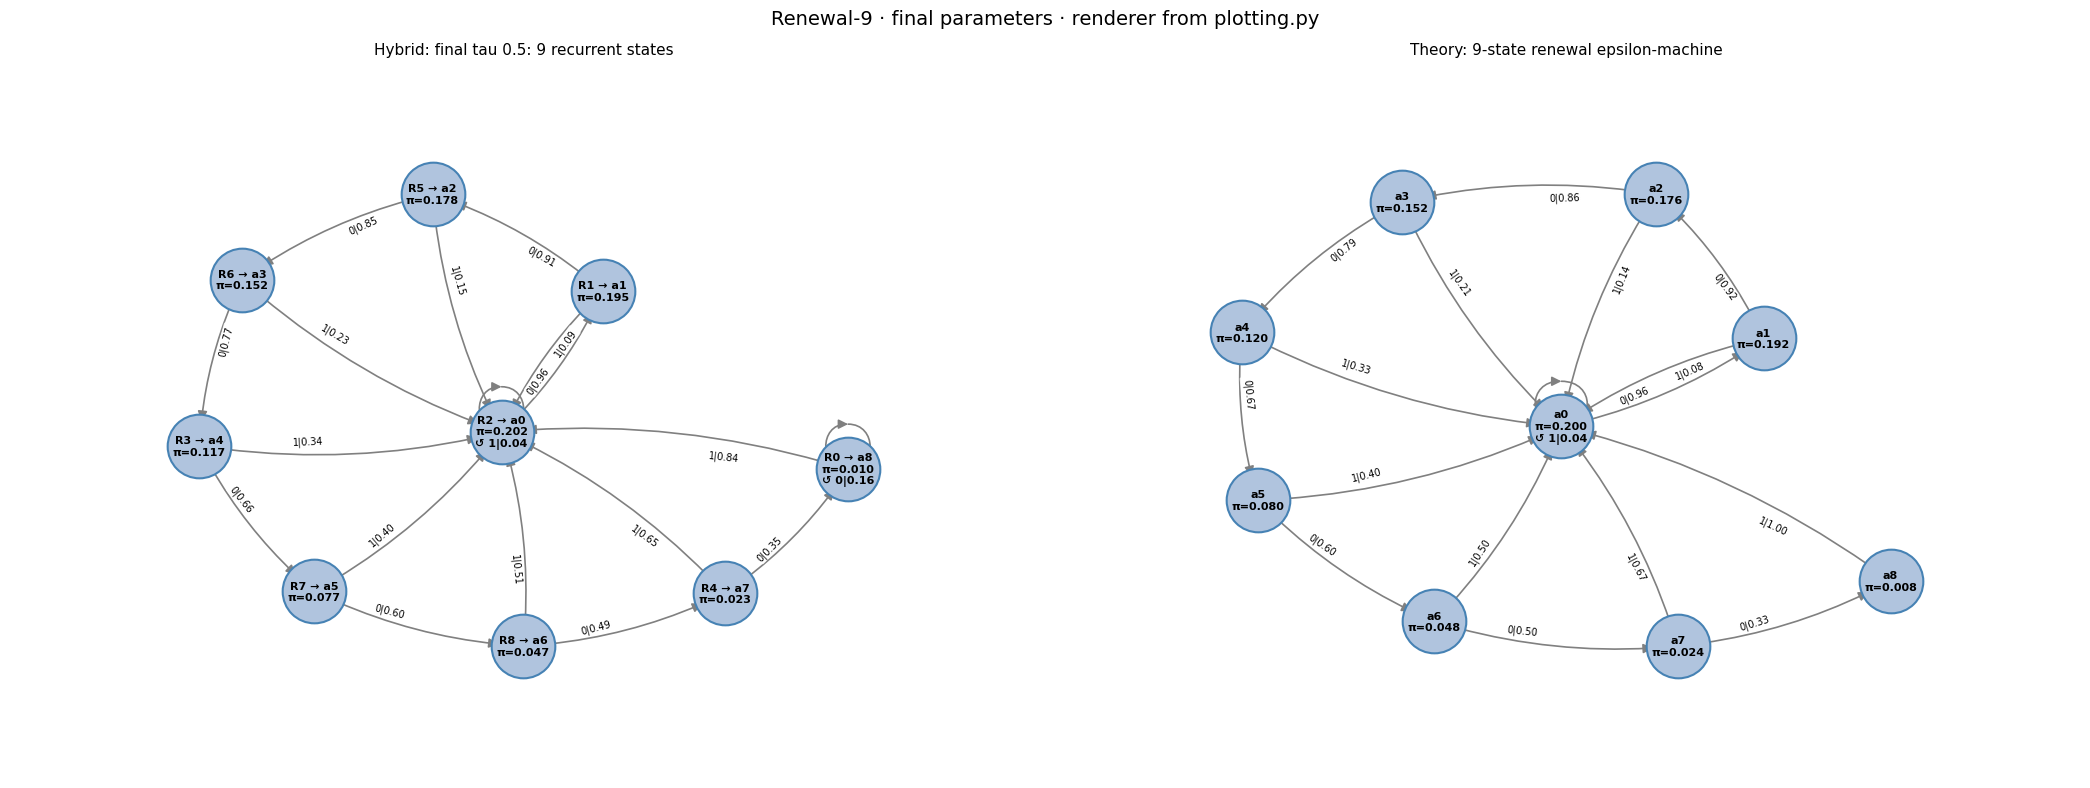

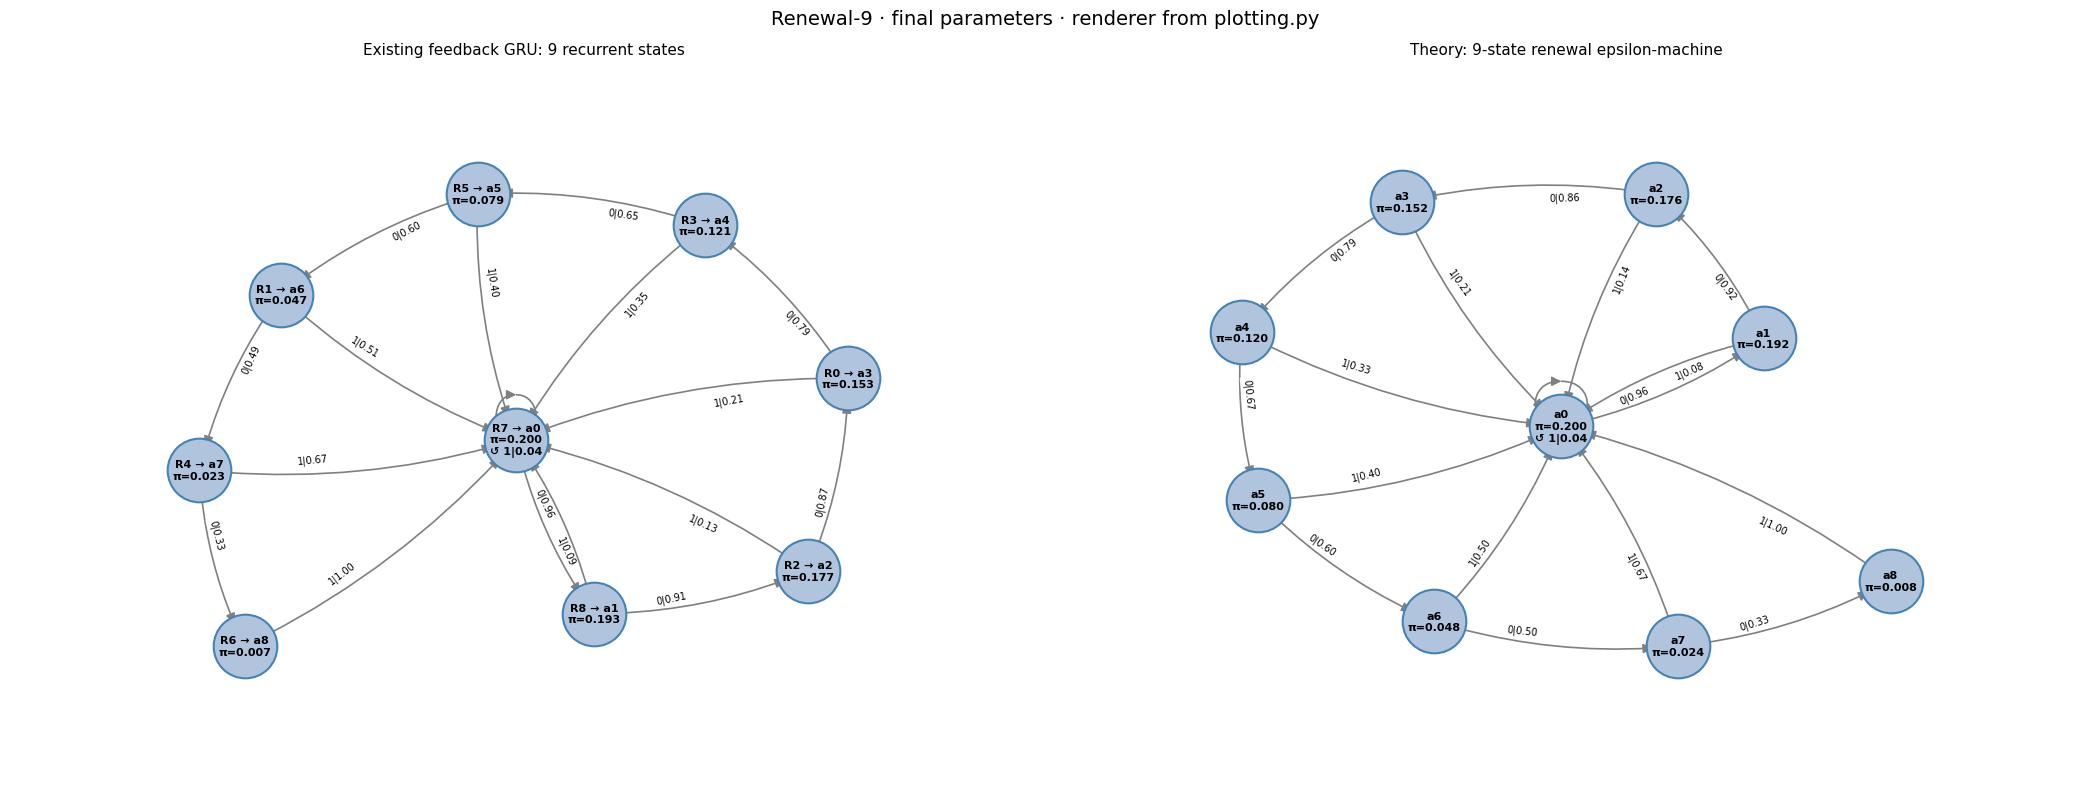

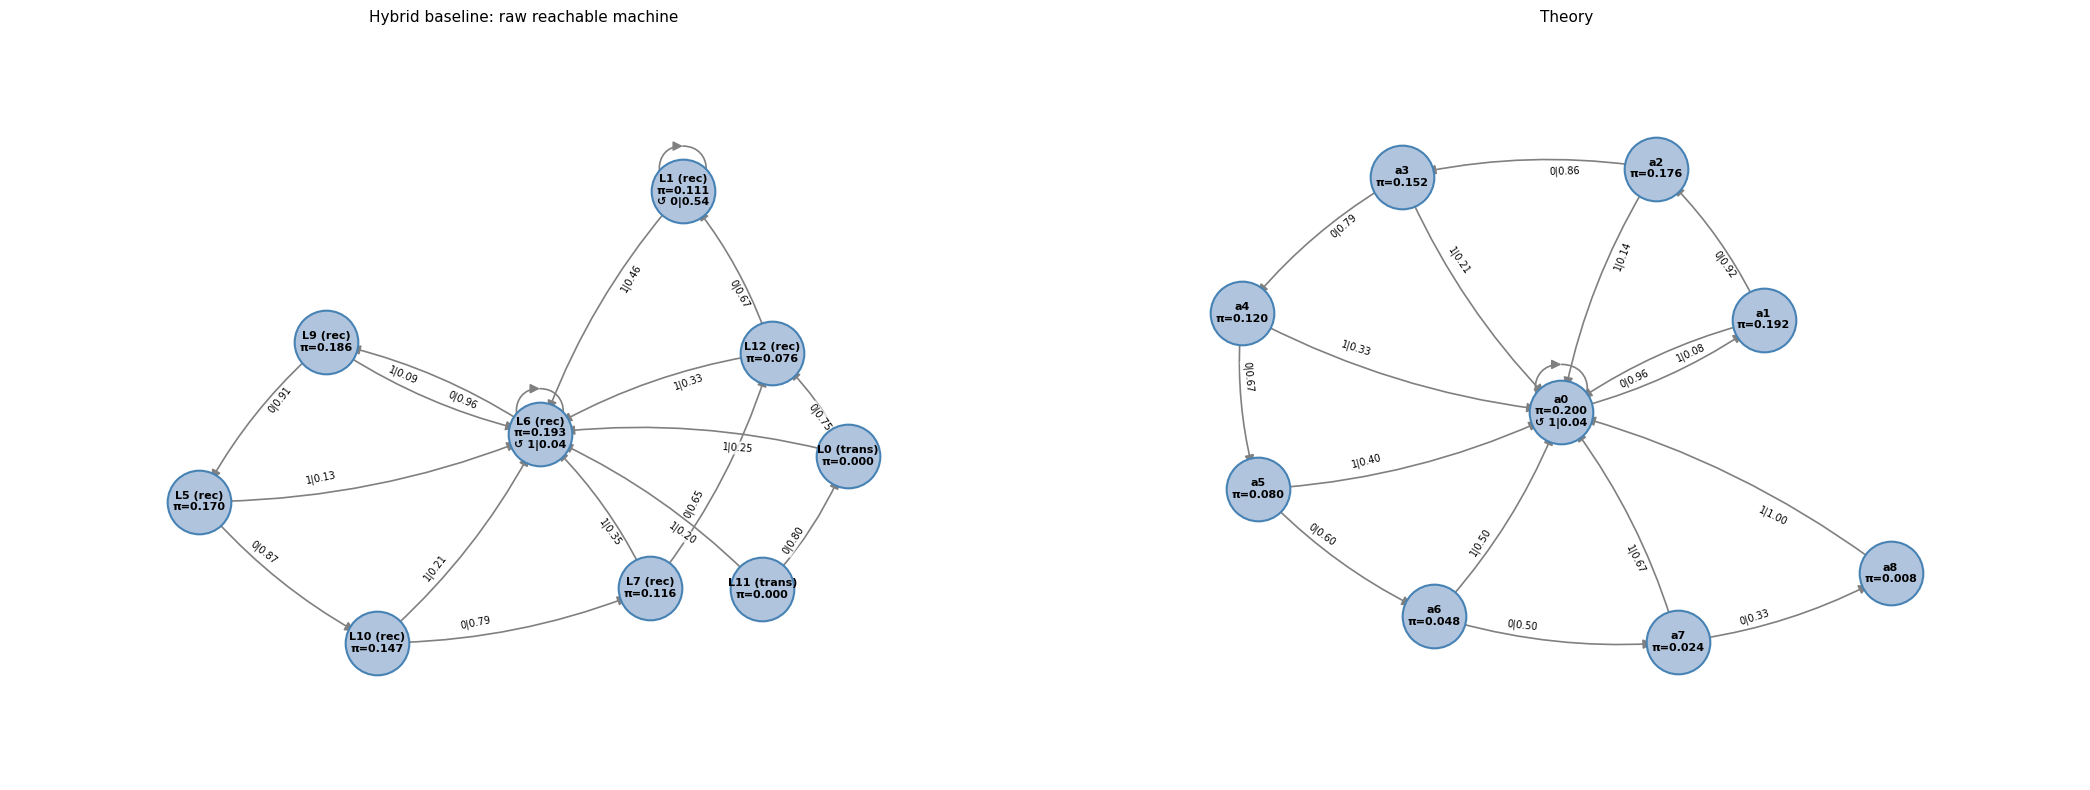

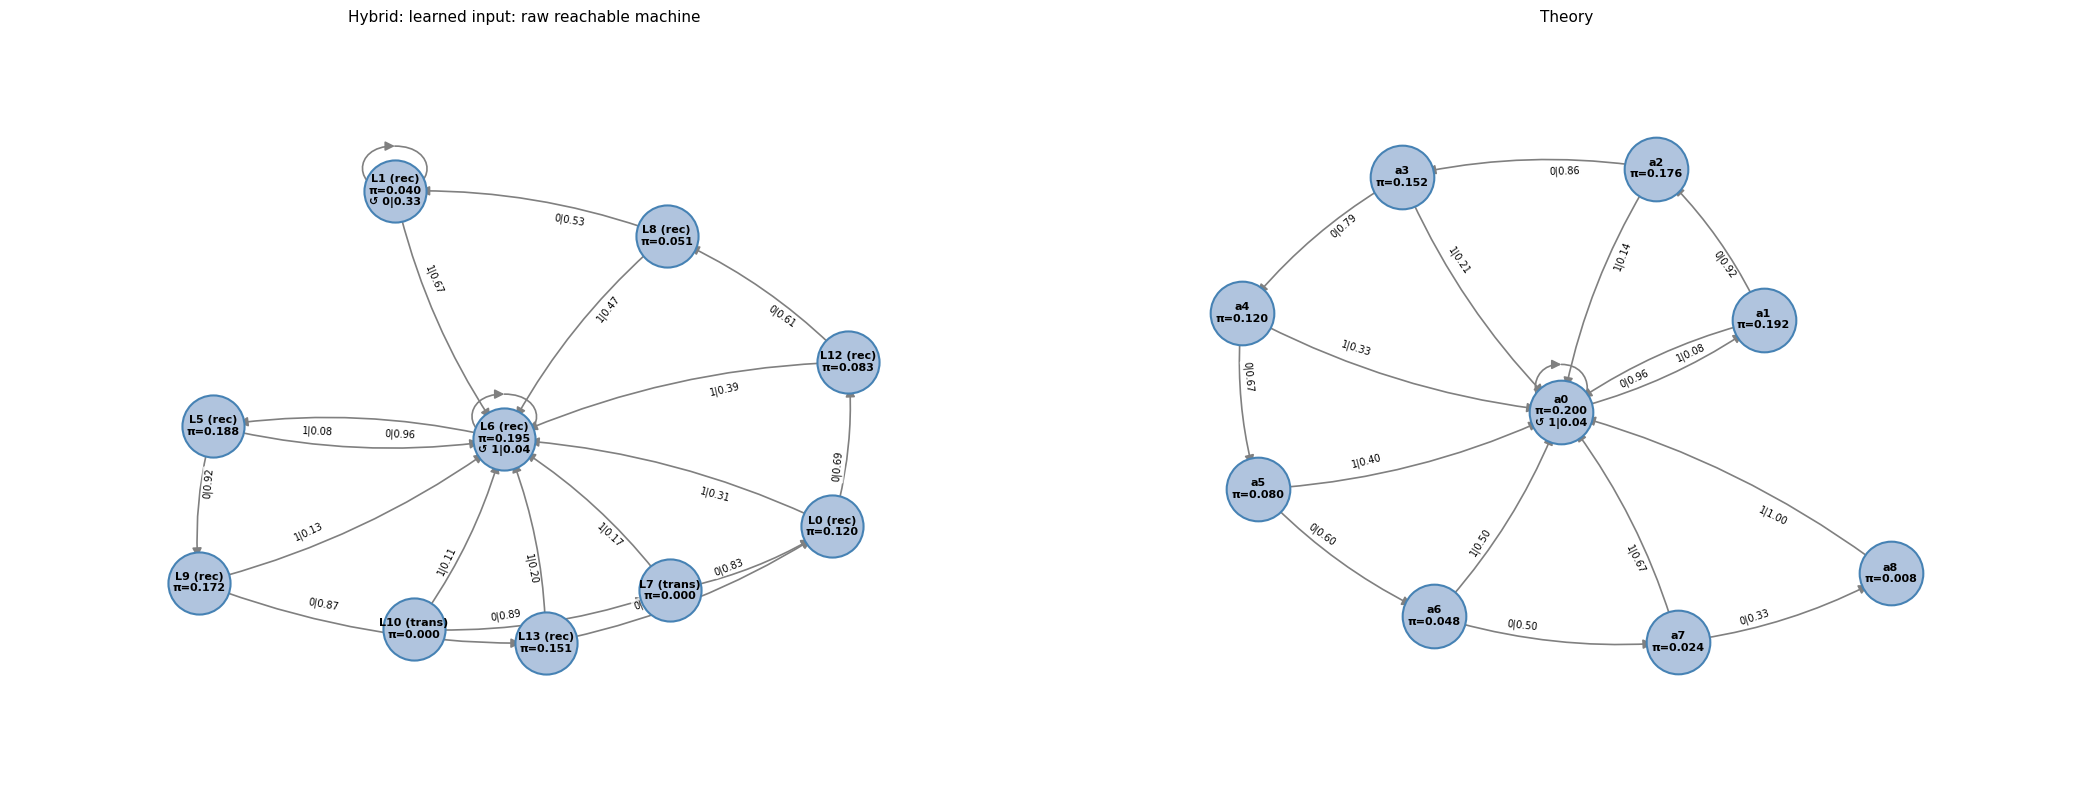

,trial,code,recurrent,p1,next0,next1,test_occupancy,start_fraction
0,baseline,0,False,0.24992,12,6,0.07998,0.00000
1,baseline,1,True,0.46075,1,6,0.11926,0.00000
2,baseline,5,True,0.13268,10,6,0.12356,0.00000
3,baseline,6,True,0.03763,9,6,0.18096,0.00000
4,baseline,7,True,0.34645,12,6,0.05896,0.00000
5,baseline,9,True,0.08760,5,6,0.15420,0.00000
6,baseline,10,True,0.20926,7,6,0.09082,0.00000
7,baseline,11,False,0.20070,0,6,0.10000,1.00000
8,baseline,12,True,0.32944,1,6,0.09226,0.00000
18,learned_input,0,True,0.30838,12,6,0.14199,0.40479


In [25]:
for name,config in configs9.items():
    a=analysis9[name]; minimal=a["minimal"]; mapping=a["mapping"]
    fig,axes=plt.subplots(1,2,figsize=(21,8))
    labels=[f"R{r}"+(f" → a{mapping[r]}" if r in mapping else " (extra)") for r in range(len(minimal["M"]))]
    draw_project_machine(axes[0],minimal["M"],a["pi_min"],labels,
                         f"{config['label']}: {len(minimal['M'])} recurrent states")
    draw_project_machine(axes[1],experiment9.M,experiment9.PI,[f"a{i}" for i in range(9)],
                         "Theory: 9-state renewal epsilon-machine")
    fig.suptitle("Renewal-9 · final parameters · renderer from plotting.py",fontsize=14)
    fig.tight_layout()
    fig.savefig(RESULTS9/f"{name}_machines.png",dpi=160,bbox_inches="tight")
    fig.savefig(RESULTS9/f"{name}_machines.pdf",bbox_inches="tight")
    plt.show()

# Show the raw baseline and the hybrid selected by validation so that transients stay visible.
for name in dict.fromkeys(["baseline",best_hybrid9]):
    a=analysis9[name]; ids=a["minimal"]["reachable"]
    rec=set(a["minimal"]["recurrent_raw"])
    labels=[f"L{s}"+(" (rec)" if s in rec else " (trans)") for s in ids]
    fig,axes=plt.subplots(1,2,figsize=(21,8))
    draw_project_machine(axes[0],a["raw"]["M"][np.ix_(ids,ids)],a["pi_raw"][ids],labels,
                         configs9[name]["label"]+": raw reachable machine")
    draw_project_machine(axes[1],experiment9.M,experiment9.PI,[f"a{i}" for i in range(9)],"Theory")
    fig.tight_layout()
    fig.savefig(RESULTS9/f"{name}_raw_machine.png",dpi=160,bbox_inches="tight")
    plt.show()

raw9_rows=[]
for name,a in analysis9.items():
    occupancy=np.bincount(a["test"]["states"].ravel(),minlength=16)/a["test"]["states"].size
    starts=np.bincount(a["test"]["starts"],minlength=16)/len(a["test"]["starts"])
    for s in a["minimal"]["reachable"]:
        raw9_rows.append(dict(trial=name,code=int(s),recurrent=bool(s in a["minimal"]["recurrent_raw"]),
                             p1=float(a["raw"]["emission"][s,1]),next0=int(a["raw"]["delta"][s,0]),
                             next1=int(a["raw"]["delta"][s,1]),test_occupancy=occupancy[s],start_fraction=starts[s]))
raw9_table=pd.DataFrame(raw9_rows)
raw9_table.to_csv(RESULTS9/"raw_transitions.csv",index=False)
display(raw9_table[raw9_table.trial.isin(["baseline",best_hybrid9,"feedback_gru"])].round(5))

### Learned versus theoretical symbol transitions

Each entry is $P(x,s'\mid s)$, not just $P(s'\mid s,x)$. Thus each complete state row,
summed over both symbols and all next states, equals one. White rows denote theoretical
ages with no assigned learned recurrent state; extra learned states remain on extra axes.
The table records both the successor and the emission probability. The theory's symbol-0
successor at age 8 is undefined because that symbol has probability zero.

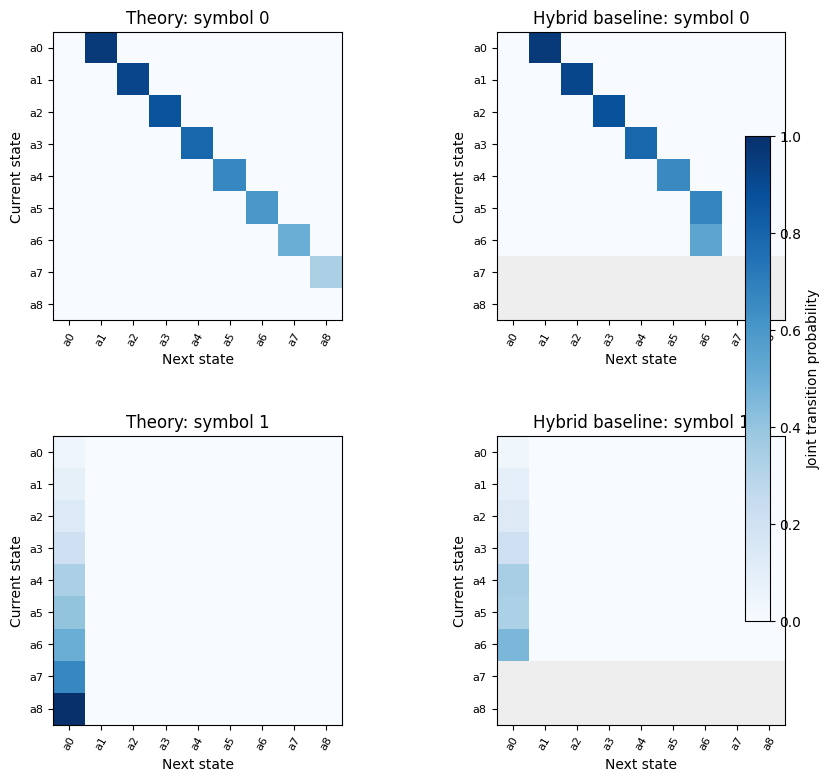

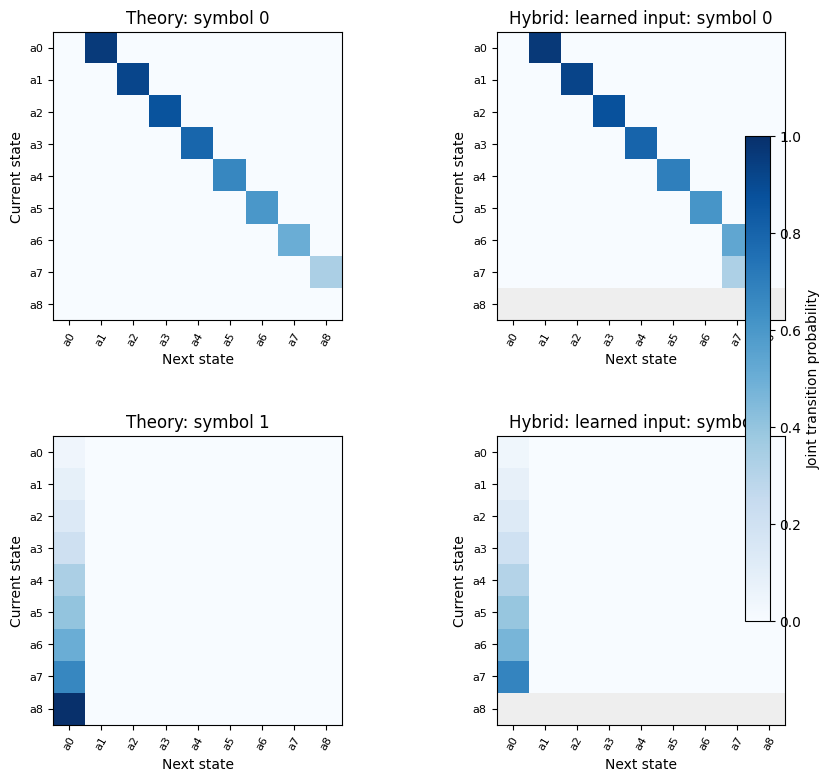

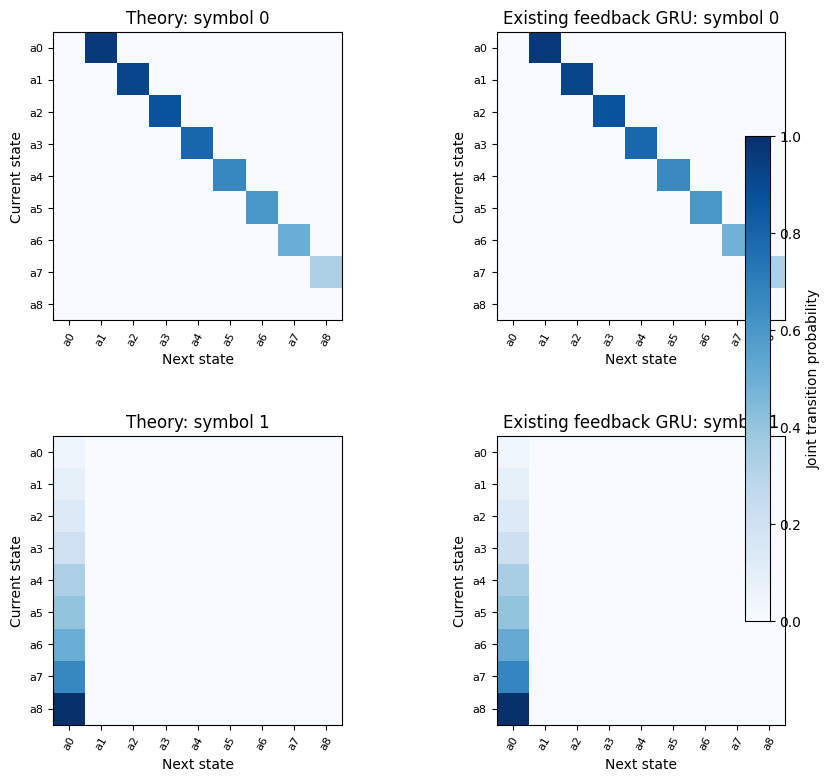

,trial,age,symbol,theory_probability,theory_next,learned_probability,learned_next
36,learned_input,0,0,0.96000,a1,0.96239,a1
37,learned_input,0,1,0.04000,a0,0.03761,a0
38,learned_input,1,0,0.91667,a2,0.91865,a2
39,learned_input,1,1,0.08333,a0,0.08135,a0
40,learned_input,2,0,0.86364,a3,0.87448,a3
41,learned_input,2,1,0.13636,a0,0.12552,a0
42,learned_input,3,0,0.78947,a4,0.79893,a4
43,learned_input,3,1,0.21053,a0,0.20107,a0
44,learned_input,4,0,0.66667,a5,0.69162,a5
45,learned_input,4,1,0.33333,a0,0.30838,a0


In [26]:
transition9_rows=[]
for name in configs9:
    a=analysis9[name]; labels=a["axis_labels"]; size=len(labels)
    fig,axes=plt.subplots(2,2,figsize=(11,9))
    cmap=plt.get_cmap("Blues").copy(); cmap.set_bad("#eeeeee")
    for x in range(2):
        for j,(matrix,title) in enumerate([(a["aligned_theory"],"Theory"),(a["aligned"],configs9[name]["label"])]):
            ax=axes[x,j]
            im=ax.imshow(np.ma.masked_invalid(matrix[:,:,x]),vmin=0,vmax=1,cmap=cmap)
            ax.set(title=f"{title}: symbol {x}",xlabel="Next state",ylabel="Current state",
                   xticks=range(size),xticklabels=labels,yticks=range(size),yticklabels=labels)
            ax.tick_params(axis="x",labelrotation=60,labelsize=8)
            ax.tick_params(axis="y",labelsize=8)
    fig.colorbar(im,ax=axes.ravel().tolist(),label="Joint transition probability",shrink=.7)
    fig.subplots_adjust(hspace=.4,wspace=.38,right=.82)
    fig.savefig(RESULTS9/f"{name}_symbol_transitions.png",dpi=160,bbox_inches="tight")
    if name in dict.fromkeys(["baseline",best_hybrid9,"feedback_gru"]): plt.show()
    else: plt.close(fig)
    inverse={age:r for r,age in a["mapping"].items()}
    for age in range(9):
        r=inverse.get(age)
        for x in range(2):
            tp=float(experiment9.M[age,:,x].sum())
            ts=int(experiment9.M[age,:,x].argmax()) if tp>0 else None
            if r is None:
                lp,ls=np.nan,"missing"
            else:
                lp=float(a["minimal"]["M"][r,:,x].sum())
                successor=int(a["minimal"]["M"][r,:,x].argmax())
                ls=f"a{a['mapping'][successor]}" if successor in a["mapping"] else f"extra R{successor}"
            transition9_rows.append(dict(trial=name,age=age,symbol=x,theory_probability=tp,
                                         theory_next=None if ts is None else f"a{ts}",
                                         learned_probability=lp,learned_next=ls))
transition9_table=pd.DataFrame(transition9_rows)
transition9_table.to_csv(RESULTS9/"transition_comparison.csv",index=False)
display(transition9_table[transition9_table.trial==best_hybrid9].round(5))

### Diagnose encoding, initialization, and recurrence separately

These are **post-training diagnostics only**; they do not train the architecture with hidden-state labels.

1. A linear classifier is fitted to the frozen Transformer's history representation on the separate
   alignment set, then tested on held-out histories. Its age accuracy asks whether the representation
   contains linearly accessible renewal-age information. It does not prove that the selection head
   or transition rule uses that information correctly.
2. For each true age, we choose the initial code giving the lowest ten-token CE on the alignment set
   while freezing all neural parameters. We evaluate this age-to-code initialization on the test set.
   This uses true-age information unavailable to the deployed model and is just an initialization
   intervention. A gain points to a problematic handoff; remaining error belongs to the available
   state representations, emissions, and recurrence. It is not a mathematical lower bound.
3. The 200-token test measures whether errors grow after a single initialization. It uses observed
   continuation tokens, just as training does; it is not free-running generation.

All plotted and tabulated architecture results above still use the actual learned initialization.
The intervention below never replaces the model's normal results.

The initialization intervention considers all 16 codebook entries, including entries that the
normal initializer may never reach. Its code choices are fitted using only the alignment set.
It can perform worse than the original initializer on held-out data, so it is not an oracle
lower bound. No test labels are used to fit this mapping or the linear classifier.


,frozen_encoder_age_accuracy,actual_initialization_excess_bits,age_informed_initialization_excess_bits,long_continuation_excess_bits
name,,,,
baseline,0.932373,0.040174,0.013352,0.015021
long_rollout,1.000000,0.071068,0.001451,0.004920
learned_input,1.000000,0.011946,0.004649,0.005463
warmer_tau,1.000000,0.013146,0.002151,0.003059
feedback_gru,NaN,0.000031,0.000405,0.000182


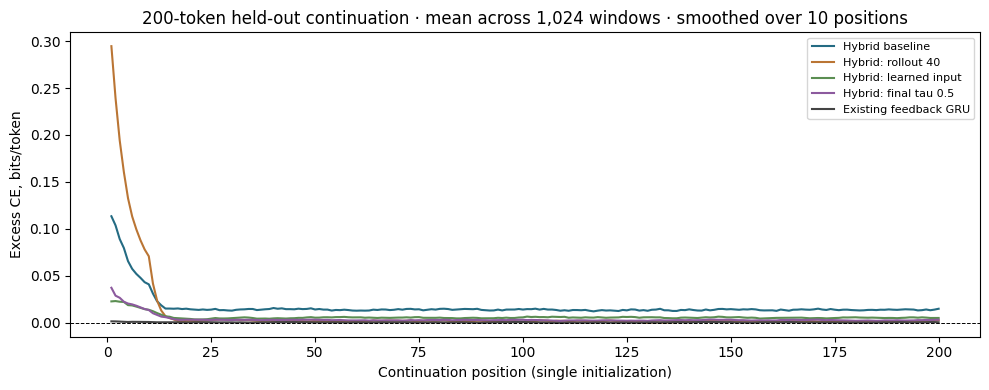

Saved renewal-9 comparisons to /Users/tisornnaphattalung/Desktop/Quantum/URECA/LLM_final_version/model_modeularised/notebook_results/renewal9_comparison


In [27]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

@torch.no_grad()
def frozen_history_features(model,tokens):
    model.eval()
    return np.concatenate([model.encoder(b[:,:20])[:,-1].cpu().numpy() for b in tokens.split(256)])

def continuation_loss_from_codes(raw,tokens,initial):
    y=tokens[:,20:].numpy()
    state=np.asarray(initial).copy()
    out=[]
    for k in range(y.shape[1]):
        target=y[:,k] if state.ndim==1 else y[:,k,None]
        out.append(-raw["log_probs"][state,target]/math.log(2))
        state=raw["delta"][state,target]
    return np.stack(out,axis=1)

probe9_rows=[]
for name,config in configs9.items():
    a=analysis9[name]; raw=a["raw"]
    all_codes=np.tile(np.arange(16),(len(alignment9_tokens),1))
    losses=continuation_loss_from_codes(raw,alignment9_tokens,all_codes).mean(axis=1)
    true_start=alignment9_states[:,20]
    age_code=np.array([losses[true_start==age].mean(axis=0).argmin() for age in range(9)])
    intervention=continuation_loss_from_codes(raw,test9_tokens,age_code[test9_states[:,20]]).mean()
    probe_accuracy=np.nan
    if config["kind"]=="hybrid":
        clf=make_pipeline(StandardScaler(),LogisticRegression(C=100,max_iter=3000))
        clf.fit(frozen_history_features(models9[name],alignment9_tokens),true_start)
        probe_accuracy=clf.score(frozen_history_features(models9[name],test9_tokens),test9_states[:,20])
    probe9_rows.append(dict(name=name,frozen_encoder_age_accuracy=probe_accuracy,
                           actual_initialization_excess_bits=a["test"]["excess_ce_bits"],
                           age_informed_initialization_excess_bits=float(intervention-a["test"]["exact_ce_bits"]),
                           long_continuation_excess_bits=a["long_test"]["excess_ce_bits"],
                           age_to_code=age_code.tolist()))
probe9=pd.DataFrame(probe9_rows).set_index("name")
probe9.to_csv(RESULTS9/"diagnostics.csv")
display(probe9.drop(columns="age_to_code").round(6))
fig,ax=plt.subplots(figsize=(10,4))
for name,a in analysis9.items():
    excess=(a["long_test"]["losses"]-a["long_test"]["exact_losses"]).mean(axis=0)
    ax.plot(np.arange(1,201),pd.Series(excess).rolling(10,min_periods=1).mean(),
            color=colors9[name],label=configs9[name]["label"])
ax.axhline(0,color="black",lw=.7,ls="--")
ax.set(xlabel="Continuation position (single initialization)",ylabel="Excess CE, bits/token",
       title="200-token held-out continuation · mean across 1,024 windows · smoothed over 10 positions")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS9/"long_continuation.png",dpi=180,bbox_inches="tight")
plt.show()
print("Saved renewal-9 comparisons to",RESULTS9)

### Observed renewal-9 results and what they imply

All five runs completed **30,000 updates** and scored **38.4 million training targets**.
These are their final parameters; no earlier checkpoint was substituted.
The exact CE on the common 4,096-window test set is **0.599948 bits/token**.

| Configuration | Excess CE, 10-token test | Excess CE, 200-token test | Recurrent states | Held-out age agreement |
|---|---:|---:|---:|---:|
| Hybrid baseline | 0.040174 | 0.015021 | 7 | 68.17% |
| Hybrid, rollout 40 | 0.071068 | 0.004920 | 9 | 76.13% |
| Hybrid, learned input | 0.011946 | 0.005463 | 8 | 72.20% |
| Hybrid, final temperature 0.5 | 0.013146 | 0.003059 | 9 | 83.24% |
| Existing feedback GRU | 0.000031 | 0.000182 | 9 | 100.00% |

The learned-input hybrid had the lowest **final validation CE among the hybrids** and is highlighted
on that basis. The feedback GRU is much closer to the true process in this seed: it recovers the
nine-state age progression on the observed test paths, with approximate emission probabilities.
Its learned probability for the theoretically forbidden zero at age 8 is small but nonzero, so this
is not an exactly identical probability model.

**The history-to-state handoff is a substantial problem.** The baseline Transformer selects L11
for all 4,096 test histories, despite the frozen encoder's linear probe recovering the true age
with 93.24% accuracy. The long-rollout Transformer always selects L6, the recurrence's reset state,
although its frozen representation yields 100% probe accuracy. In the long-rollout model,
replacing only the initialization with the separately fitted, age-informed code choice reduces
test excess CE from 0.071068 to 0.001451 bits/token. This intervention uses true-state information
and is diagnostic only. It shows that longer history or more representational information is
not by itself enough: the learned selection head must use it effectively.

**A longer rollout improved the recurrence more than the handoff.** Its 200-token average error
is much smaller than its ten-token error. The true process often emits a 1, which resets the
learned machine and washes out a bad initial age. Its nine recurrent states and near-correct
emissions help after synchronization; they do not repair the constant initial-state choice.
The warmer-temperature hybrid also has nine recurrent states and better long-continuation CE,
but its age-8 emission P(1)=0.838 is still wrong (theory: 1).

**Learning the input vectors helped, but did not fully recover the process.** It improved
final short-window prediction over the baseline, but the recurrent machine has eight states:
the last learned state loops on zero and conflates the tail ages. Perfect linear age-probe
accuracy does not imply correct use of that information by the state selector or recurrence.

**More updates did not guarantee better results.** Baseline validation excess CE was 0.003051
at update 8,000 and ended at 0.040408. The long-rollout version reached 0.001991 at 12,000
and ended at 0.062820. The warmer version reached 0.000378 at 17,500 and ended at 0.012278.
These are validation-curve observations; the earlier parameter checkpoints were not saved,
so there are no corresponding earlier test scores or extracted machines. The deterioration
coincides with continued annealing and optimization. This comparison supports testing gentler
annealing, a learning-rate schedule, or validation checkpointing next, but does not identify
one unique cause or establish a multi-seed result.

**Large L2 is not just a temperature-display effect.** The baseline's final test L2 is 1.414213
at the scheduled temperature and 1.414168 at fixed temperature 1. The nearly maximal
probability disagreement persists when the diagnostic temperature is held fixed.
Remember that this compares the two learned selection paths, not either path with true age.

For your rewrite, preserve the indexing and teacher-forcing checks in the earlier sections.
Use the existing feedback GRU as a reference for discrete transitions. Keep the L2 diagnostic
separate from CE. No consistency loss, KL penalty, usage penalty, or supervised state-label
objective was added to the hybrid. The changes tested here are parameter/configuration choices;
they do not modify your `hybrid_transformer_GRU_v2.py`.
